# Assignment II (Set A) - Robust Reinforcement Learning under Sticky Actuators
**Course**: CS7 - CS12 / Reinforcement Learning &nbsp;|&nbsp; **Group #**: 55 &nbsp;|&nbsp; **Submission deadline**: November 14, 2026

### Group Contribution Declaration
| Group Member Name | Student ID | Email | Contribution (%) |
| :--- | :--- | :--- | :--- |
| MEENA G | 2025ag05199 | 2025ag05199@wilp.bits-pilani.ac.in | 100% |
| RAVINDRA L K | 2025ag05202 | 2025ag05202@wilp.bits-pilani.ac.in | 100% |
| KODURU PAVAN KUMAR REDDY | 2025ag05203 | 2025ag05203@wilp.bits-pilani.ac.in | 100% |
| T VISHNUVARDAN REDDY | 2025ag05614 | 2025ag05614@wilp.bits-pilani.ac.in | 100% |

---
**How this report is organised.** We first build the sticky-actuator wrapper and test it (a). Then we set up the discretisation and the fixed validation set,
train Q-learning (b) and SARSA (c), and compare the four agents with plots and a table (d). After the required comparison we added a few extra checks
(more seeds, cross-evaluation, a smaller grid) because one seed turned out to be not very reliable. The discussion questions are answered in (e).
Unless it says otherwise, numbers are for the main seed 42.

---
### 📷 Virtual-lab screenshot 1 - Virtual-lab session
> **[PLACEHOLDER - paste the screenshot here and delete this box]**
> Show the virtual-lab window with this notebook open (file name visible) and the **date and time** of the machine/lab visible (for example the taskbar clock or the lab header).
>
> *Tip: in Jupyter drag the image file into this cell, or use `![screenshot](your_file.png)` with the picture next to the notebook. When exporting to PDF, check that the image appears.*

---

In [1]:
# ---------------------------------------------------------------
# Setup: imports, global configuration and reproducibility info
# ---------------------------------------------------------------
import os, sys, math, time, json, platform, datetime       # standard-library helpers
from typing import Tuple, Dict, Any, List, Optional        # type hints used in signatures

import numpy as np                                         # numerical arrays + random generators
import pandas as pd                                        # tables for statistics
import matplotlib.pyplot as plt                            # plotting
import matplotlib.patches as mpatches                      # legend patches for the policy maps
from matplotlib.colors import ListedColormap               # discrete colour map for actions
try:
    import gymnasium as gym                                # MountainCar-v0 + gym.Wrapper
except ImportError:                                        # e.g. fresh Colab runtime
    get_ipython().system('pip install -q gymnasium')              # install gymnasium if it is missing
    import gymnasium as gym                                       # import again after the installation

# ----- global experiment configuration (identical for ALL four agents) -----
ENV_ID        = "MountainCar-v0"                                  # name of the Gymnasium environment
SEED          = 42                 # primary random seed (used for the main comparison)
EXTRA_SEEDS   = [43, 44, 45, 46]   # additional seeds, only for the robustness section
EPISODES      = 5000               # training episodes (assignment minimum)
ALPHA         = 0.1                # learning rate
GAMMA         = 0.99               # discount factor
EPS_START     = 1.0                # initial epsilon
EPS_MIN       = 0.01               # epsilon floor
EPS_DECAY     = 0.9993             # multiplicative decay applied once per episode
N_BINS        = 28                 # 28 x 28 grid (justified below)
STICKY_SEED_OFFSET = 10_000        # wrapper RNG seed = agent seed + offset (separate stream)
EVAL_EPISODES = 100                # greedy evaluation episodes
EVAL_BASE_SEED = 1000              # env reset seeds for evaluation: 1000..1099
EVAL_STICKY_SEED = 2024            # sticky-actuator RNG seed during evaluation
QUICK_TEST    = False              # True -> tiny run for debugging only
if QUICK_TEST:                                                    # tiny debug configuration
    EPISODES, EXTRA_SEEDS = 300, [43]                             # only for quick debugging runs
ALL_SEEDS = [SEED] + EXTRA_SEEDS                                  # primary seed followed by the extra seeds

np.random.seed(SEED)               # legacy global seed (all real randomness uses its own Generator)

pd.set_option("display.width", 200)                               # wider tables in the printed output
pd.set_option("display.max_columns", 30)                          # wider tables in the printed output
RUN_START = datetime.datetime.now()                               # start time (used for the run log)
print("Run started       :", RUN_START.strftime("%Y-%m-%d %H:%M:%S"))
print("Python / platform :", sys.version.split()[0], "/", platform.platform())
print("numpy / pandas    :", np.__version__, "/", pd.__version__)
print("gymnasium         :", gym.__version__)
print(f"Config: episodes={EPISODES}, alpha={ALPHA}, gamma={GAMMA}, eps {EPS_START}->min {EPS_MIN} (x{EPS_DECAY}/episode), grid={N_BINS}x{N_BINS}, seeds={ALL_SEEDS}")
print(f"epsilon after {EPISODES} episodes = {max(EPS_MIN, EPS_START*EPS_DECAY**EPISODES):.4f}")

Run started       : 2026-11-06 00:13:22
Python / platform : 3.14.2 / Windows-11-10.0.26100-SP0
numpy / pandas    : 2.4.4 / 3.0.2
gymnasium         : 1.4.0
Config: episodes=5000, alpha=0.1, gamma=0.99, eps 1.0->min 0.01 (x0.9993/episode), grid=28x28, seeds=[42, 43, 44, 45, 46]
epsilon after 5000 episodes = 0.0302


---
### 📷 Virtual-lab screenshot 2 - Start of the run
> **[PLACEHOLDER - paste the screenshot here and delete this box]**
> Screenshot of the setup cell output above: the line **'Run started : <date time>'**, the Python / gymnasium versions and the configuration line.
>
> *Tip: in Jupyter drag the image file into this cell, or use `![screenshot](your_file.png)` with the picture next to the notebook. When exporting to PDF, check that the image appears.*

---

## (a) Modified environment: implementation and verification
The wrapper is a `gym.Wrapper` around MountainCar-v0. It keeps one hidden variable `a_prev`, the action that was really executed in the previous step (set to 1 on every reset).
In every step it does the following, in this order: it stores the action `a` chosen by the agent; if `a` differs from `a_prev` it draws `r` from U[0,1) and, when `r < 0.20`, executes `a_prev` instead;
it runs the executed action in the normal environment; and it returns `R = R_base - 0.2 * (a != 1) + B`, where `B = +20` only if the episode terminated (not truncated), position is at least 0.5 and velocity is at most 0.04.
The energy cost uses the chosen action `a`, not the executed one. Everything else (observation, action space, dynamics, termination, `info`) is passed through unchanged.
The wrapper has its own seeded random generator, so the stickiness is reproducible and does not mix with the agent's exploration randomness.

In [2]:
class StickyMountainCarWrapper(gym.Wrapper):
    """
    MountainCar-v0 with a sticky actuator and a modified reward (assignment spec).

    Internal state : a_prev = action that was actually EXECUTED on the previous step
                     (reset to 1 = "do not accelerate" on every reset()).
    step(action) performs, in this order:
      1. store the agent's selected action a
      2. sticky actuator: if a != a_prev, draw r~U[0,1); if r < 0.20 execute a_prev instead
         (if a == a_prev no random number is drawn); then a_prev <- a_exec
      3. execute a_exec in the base env
      4. R = R_base - 0.2 * 1[a != 1] + B      (penalty uses the SELECTED action a)
      5. B = +20 iff terminated and not truncated and pos >= 0.5 and vel <= 0.04
      6. return (obs, R, terminated, truncated, info) -- info is passed through untouched.
    Observation space, action space, dynamics, termination and truncation are unchanged.
    """
    STICKY_PROB    = 0.20    # probability that a changed action is replaced by a_prev
    ENERGY_PENALTY = 0.2     # cost of *selecting* a push action (0 or 2)
    GENTLE_BONUS   = 20.0    # gentle-arrival bonus
    GOAL_POS       = 0.5     # flag position
    GENTLE_VEL     = 0.04    # max arrival velocity for the bonus

    def __init__(self, env: gym.Env, sticky_seed: int = 0, rng=None):
        """env: base environment; sticky_seed: seed of the wrapper's private RNG;
        rng: optional object with .uniform(low, high) (used to replay scripted random numbers in tests)."""
        super().__init__(env)                                     # initialise the parent gym.Wrapper
        self.a_prev = 1                                            # "do not accelerate" at start
        # Private RNG so that actuator randomness never interferes with the agent's exploration RNG
        self._rng = rng if rng is not None else np.random.default_rng(sticky_seed)  # own random generator (or the scripted one used in tests)

    def reset(self, **kwargs):
        """Reset the base env and the internal sticky state (a_prev = 1). Returns (obs, info) unchanged."""
        obs, info = self.env.reset(**kwargs)                      # reset the underlying environment
        self.a_prev = 1                                           # the actuator starts at 'do not accelerate'
        return obs, info

    def step(self, action):
        """Apply the sticky actuator, run the base env, and return the modified reward."""
        a = int(action)                                            # Step 1: the agent's selected action

        # Step 2: sticky actuator
        if a == self.a_prev:                                      # same command as before: nothing can get stuck
            a_exec = a                                             # repeated action: never replaced
        else:
            r = self._rng.uniform(0.0, 1.0)                        # r ~ U[0,1)
            a_exec = self.a_prev if r < self.STICKY_PROB else a    # stuck (20%) -> keep previous command
        self.a_prev = a_exec                                       # remember what was really executed

        # Step 3: execute in the original environment
        obs, r_base, terminated, truncated, info = self.env.step(a_exec)  # run the executed action in MountainCar-v0

        # Step 4: energy penalty depends on the SELECTED action a, not on a_exec
        penalty = self.ENERGY_PENALTY if a != 1 else 0.0          # 0.2 for a chosen push (0 or 2), 0 for action 1

        # Step 5: gentle-arrival bonus (all four conditions must hold simultaneously)
        bonus = 0.0
        if terminated and (not truncated) and obs[0] >= self.GOAL_POS and obs[1] <= self.GENTLE_VEL:  # bonus only for a slow arrival at the flag
            bonus = self.GENTLE_BONUS                             # +20 gentle-arrival bonus

        # Step 6: return the modified reward; nothing about stuck actions / bonus is leaked via info
        return obs, r_base - penalty + bonus, terminated, truncated, info

### How we verify it
All tests call `step()` of the real wrapper and log `a_prev`, `a`, `a_exec`, the reward and the flags for every step.
Test 0 replays the 5-step example from the assignment with fixed random numbers. Test 1 measures how often a changed action is replaced (random policy, 200 episodes).
Test 2 checks that a repeated action is never replaced. Test 3 checks the energy cost in all four cases (push or idle, executed or stuck).
Test 4 checks the bonus with a hand-coded policy, with forced edge cases (slow arrival, fast arrival) and with truncation. Test 5 checks that spaces, `info` and the dynamics are unchanged.

In [3]:
class ScriptedRNG:
    """Fake RNG that replays a fixed list of 'random' numbers; used to reproduce the assignment's example table."""
    def __init__(self, values):
        """Store the numbers to replay and a counter of how many were used."""
        self.values, self.calls = list(values), 0                 # remember the numbers and how many were used
    def uniform(self, low=0.0, high=1.0):
        """Return the next scripted number (same call signature as numpy's uniform)."""
        v = self.values[self.calls]; self.calls += 1              # return the next scripted number
        return v

def run_logged_episodes(env, policy_fn, n_episodes: int, seed0: int, policy_seed: int = 0) -> pd.DataFrame:
    """
    Run n_episodes on the (wrapped) env and log every step:
    a_prev (before the step), a (selected), a_exec (what the actuator really executed), reward, flags, obs.
    a_exec is read from env.a_prev AFTER the step (the wrapper stores the executed action there).
    """
    rng = np.random.default_rng(policy_seed)                       # policy randomness (separate stream)
    rows = []
    for ep in range(n_episodes):                                  # loop over the episodes
        obs, _ = env.reset(seed=seed0 + ep)                        # fixed reset seed per episode
        done, t = False, 0                                        # episode flag and step counter
        while not done:                                           # step until the episode ends
            a_prev_before = env.a_prev                             # value used by the sticky rule this step
            a = int(policy_fn(obs, rng))                           # agent's selected action
            obs, R, term, trunc, info = env.step(a)               # take the step in the wrapped environment
            rows.append((ep, t, a_prev_before, a, env.a_prev, R, term, trunc, float(obs[0]), float(obs[1])))  # store one log row for this step
            done, t = (term or trunc), t + 1                      # episode ends on termination or truncation
    return pd.DataFrame(rows, columns=["ep","t","a_prev","a","a_exec","R","term","trunc","pos","vel"])

def random_policy(obs, rng):
    """Uniformly random action in {0,1,2}."""
    return rng.integers(3)

def velocity_policy(obs, rng):
    """Hand-coded energy-pumping policy: push in the direction of the velocity."""
    return 2 if obs[1] >= 0 else 0

In [4]:
# ================= (a) VERIFICATION =================
# ---- Test 0: replay the assignment's 5-step example with scripted random numbers ----
# random numbers are only consumed on steps where a != a_prev (steps 1,3,4,5) -> 0.55, 0.11, 0.74, 0.05
scripted = ScriptedRNG([0.55, 0.11, 0.74, 0.05])                  # random numbers used by the assignment example
env0 = StickyMountainCarWrapper(gym.make(ENV_ID), rng=scripted)   # wrapper that draws numbers from the scripted list
env0.reset(seed=0)                                                # start a new episode (a_prev = 1)
example_actions, expected_exec = [2, 2, 0, 0, 1], [2, 2, 2, 0, 0]  # agent actions and the executed actions the assignment lists
trace = []
for k, a in enumerate(example_actions, start=1):                  # replay the 5 steps
    a_prev_before = env0.a_prev                                   # a_prev before this step
    env0.step(a)
    trace.append((k, a_prev_before, a, env0.a_prev))              # a_prev after the step equals the executed action
df_ex = pd.DataFrame(trace, columns=["Step", "a_prev", "Agent action a", "a_exec (observed)"])  # table of the replay
df_ex["a_exec (expected)"] = expected_exec                        # add the expected column from the assignment
print("Test 0 - assignment example replay:"); print(df_ex.to_string(index=False))
assert list(df_ex["a_exec (observed)"]) == expected_exec, "example table NOT reproduced"  # executed actions must equal the assignment table
assert scripted.calls == 4, "random number must be drawn only when a != a_prev"  # a random number is drawn only when a != a_prev
print("-> example reproduced exactly; random numbers drawn:", scripted.calls, "(expected 4)\n")
env0.close()

# ---- Tests 1-3: 200 random-policy episodes through the REAL wrapper ----
env_v = StickyMountainCarWrapper(gym.make(ENV_ID), sticky_seed=123)  # fresh wrapper for the random-policy test
df_rand = run_logged_episodes(env_v, random_policy, n_episodes=200, seed0=0, policy_seed=7)  # 200 random-policy episodes, every step logged
print(f"Random-policy log: {len(df_rand)} steps over {df_rand.ep.nunique()} episodes")

# Test 1: replacement rate when the action changes (a != a_prev)
chg = df_rand[df_rand.a != df_rand.a_prev]                        # steps where the action changed
n_chg, n_rep = len(chg), int((chg.a_exec == chg.a_prev).sum())    # number of changes and number of replacements
print(f"\nTest 1 - attempted action changes: {n_chg}; replaced by a_prev: {n_rep} -> {100*n_rep/n_chg:.2f}%  (expected ~20%)")
se = math.sqrt(0.2*0.8/n_chg)                                     # standard error of a proportion with p = 0.2
print(f"         binomial 95% interval for p=0.20: [{100*(0.2-1.96*se):.2f}%, {100*(0.2+1.96*se):.2f}%]")
assert abs(n_rep/n_chg - 0.2) < 1.96*se*1.5                       # measured rate must be close to 20%

# Test 2: never a replacement when the action is repeated (a == a_prev)
rep = df_rand[df_rand.a == df_rand.a_prev]                        # steps where the action was repeated
n_rep_bad = int((rep.a_exec != rep.a).sum())                      # replacements among repeated actions (should be 0)
print(f"Test 2 - repeated actions: {len(rep)}; replaced: {n_rep_bad}  (expected 0)")
assert n_rep_bad == 0                                             # a repeated action is never replaced

# Test 3: energy penalty depends on the SELECTED action; split into the 4 cases
bonus_free = df_rand[~df_rand.term]                                # no terminal steps here (bonus impossible)
cases = {
 "push selected & executed (a!=1, a_exec==a)":         ((bonus_free.a != 1) & (bonus_free.a_exec == bonus_free.a), -1.2),  # case 1: push chosen and executed -> -1.2
 "push selected but STUCK on other (a!=1, a_exec!=a)": ((bonus_free.a != 1) & (bonus_free.a_exec != bonus_free.a), -1.2),  # case 2: push chosen but stuck on another action -> -1.2
 "idle selected & executed (a==1, a_exec==1)":         ((bonus_free.a == 1) & (bonus_free.a_exec == 1), -1.0),  # case 3: idle chosen and executed -> -1.0
 "idle selected but STUCK pushing (a==1, a_exec!=1)":  ((bonus_free.a == 1) & (bonus_free.a_exec != 1), -1.0),  # case 4: idle chosen, actuator keeps pushing -> -1.0 (no penalty)
}
rows = []
for name, (m, expected_R) in cases.items():                       # check every case
    sub = bonus_free[m]                                           # steps that belong to this case
    rows.append((name, len(sub), sub.R.min(), sub.R.max(), expected_R, bool((sub.R.round(6) == expected_R).all())))  # count and reward range for this case
df_pen = pd.DataFrame(rows, columns=["Case", "#steps", "min R", "max R", "expected R", "all as expected"])
print("\nTest 3 - energy penalty per case (base reward is -1):"); print(df_pen.to_string(index=False))
assert df_pen["all as expected"].all() and (df_pen["#steps"] > 0).all()
print("Random policy: bonuses awarded =", int((df_rand.R > 0).sum()), "(expected 0: random policy never reaches the flag)",
      "| truncated episodes:", int(df_rand.trunc.sum()), "/ 200")
env_v.close()                                                     # close the environment

Test 0 - assignment example replay:
 Step  a_prev  Agent action a  a_exec (observed)  a_exec (expected)
    1       1               2                  2                  2
    2       2               2                  2                  2
    3       2               0                  2                  2
    4       2               0                  0                  0
    5       0               1                  0                  0
-> example reproduced exactly; random numbers drawn: 4 (expected 4)

Random-policy log: 40000 steps over 200 episodes

Test 1 - attempted action changes: 26688; replaced by a_prev: 5359 -> 20.08%  (expected ~20%)
         binomial 95% interval for p=0.20: [19.52%, 20.48%]
Test 2 - repeated actions: 13312; replaced: 0  (expected 0)

Test 3 - energy penalty per case (base reward is -1):
                                              Case  #steps  min R  max R  expected R  all as expected
        push selected & executed (a!=1, a_exec==a)   23207   -1.2 

In [5]:
# ---- Test 4: gentle-arrival bonus ----
# (i) hand-coded velocity-pumping policy: statistics over 100 episodes
env_h = StickyMountainCarWrapper(gym.make(ENV_ID), sticky_seed=321)  # wrapper for the hand-coded policy test
df_h = run_logged_episodes(env_h, velocity_policy, n_episodes=100, seed0=500)  # 100 episodes with the velocity policy
env_h.close()                                                     # close the environment
df_h["push_pen"] = np.where(df_h.a != 1, 0.2, 0.0)                # energy penalty that applies to each step
df_h["bonus_obs"] = (df_h.R + 1.0 + df_h.push_pen).round(6)               # recover B = R - R_base + penalty
df_h["bonus_exp"] = np.where(df_h.term & ~df_h.trunc & (df_h.pos >= 0.5) & (df_h.vel <= 0.04), 20.0, 0.0)  # bonus the specification says must be paid
terminal = df_h[df_h.term | df_h.trunc]                           # last step of every episode
print("Test 4(i) - hand-coded policy, final steps of 100 episodes:")
print(pd.DataFrame({
    "episodes": [len(terminal)],                                  # number of episodes
    "reached flag": [int(terminal.term.sum())],                   # episodes that reached the flag
    "gentle (vel<=0.04) -> bonus": [int((terminal.bonus_obs == 20).sum())],  # slow arrivals that received +20
    "fast (vel>0.04) -> no bonus": [int(((terminal.term) & (terminal.vel > 0.04) & (terminal.bonus_obs == 0)).sum())],  # fast arrivals that received nothing
    "truncated -> no bonus": [int(((terminal.trunc) & (terminal.bonus_obs == 0)).sum())],  # truncated episodes that received nothing
}).to_string(index=False))                                        # print the table
print("Bonus equals the spec rule on EVERY step:", bool((df_h.bonus_obs == df_h.bonus_exp).all()))
assert (df_h.bonus_obs == df_h.bonus_exp).all()                   # paid bonus must equal the rule on every step
if terminal.term.any():                                           # only if some episode reached the flag
    print("Arrival velocities (hand-coded policy): min %.4f / median %.4f / max %.4f" % (
        terminal[terminal.term].vel.min(), terminal[terminal.term].vel.median(), terminal[terminal.term].vel.max()))  # arrival speed statistics

# (ii) forced edge cases by placing the car next to the flag (a_prev set so no sticky draw can interfere)
def forced_step(pos, vel, action, a_prev):                        # helper that places the car next to the flag
    """Place the car at (pos, vel), set a_prev, take one step; return (terminated, truncated, final pos, final vel, reward)."""
    e = StickyMountainCarWrapper(gym.make(ENV_ID), sticky_seed=0)  # fresh wrapper for one forced step
    e.reset(seed=0)                                               # normal reset first
    e.unwrapped.state = np.array([pos, vel], dtype=np.float64)       # teleport the car
    e.a_prev = a_prev                                             # choose the previous executed action
    obs, R, term, trunc, _ = e.step(action)                       # one step from the forced state
    e.close()
    return term, trunc, float(obs[0]), float(obs[1]), R

edge = [
  ("slow arrival, push selected & executed (expect +20 bonus)", forced_step(0.499, 0.010, 2, 2), 0.2, 20.0),  # slow arrival: +20 expected
  ("fast arrival, vel>0.04 (expect NO bonus)",                  forced_step(0.490, 0.060, 2, 2), 0.2, 0.0),  # fast arrival: no bonus expected
  ("slow arrival, idle selected while a_prev=2 keeps pushing (no penalty, bonus paid)", forced_step(0.499, 0.010, 1, 2), 0.0, 20.0),  # idle chosen while stuck pushing: no penalty, bonus still paid
]
rows = []
for name, (term, trunc, p, v, R), pen, exp_b in edge:             # collect the results of the forced cases
    rows.append((name, term, trunc, round(p, 4), round(v, 4), round(R, 3), round(R + 1 + pen, 3), exp_b))  # derive the bonus from the reward
df_edge = pd.DataFrame(rows, columns=["Case", "terminated", "truncated", "pos", "vel", "R", "bonus B (derived)", "expected B"])  # table of the forced cases
print("\nTest 4(ii) - forced edge cases:"); print(df_edge.to_string(index=False))
assert (df_edge["bonus B (derived)"] == df_edge["expected B"]).all()  # derived bonus must equal the expected bonus

# (iii) truncation at 200 steps: never a bonus
env_t = StickyMountainCarWrapper(gym.make(ENV_ID), sticky_seed=0)  # wrapper for the truncation test
env_t.reset(seed=3)                                               # start an episode
for _ in range(200):                                              # do nothing for 200 steps
    obs, R, term, trunc, _ = env_t.step(1)                        # idle action every step
print(f"\nTest 4(iii) - idle for 200 steps: truncated={trunc}, terminated={term}, last reward={R} (expected -1.0, no bonus)")
assert trunc and not term and R == -1.0                           # truncated, not terminated, no bonus
env_t.close()                                                     # close the environment

Test 4(i) - hand-coded policy, final steps of 100 episodes:
 episodes  reached flag  gentle (vel<=0.04) -> bonus  fast (vel>0.04) -> no bonus  truncated -> no bonus
      100           100                           25                           75                      0
Bonus equals the spec rule on EVERY step: True
Arrival velocities (hand-coded policy): min 0.0150 / median 0.0477 / max 0.0500

Test 4(ii) - forced edge cases:
                                                                             Case  terminated  truncated    pos    vel    R  bonus B (derived)  expected B
                        slow arrival, push selected & executed (expect +20 bonus)        True      False 0.5098 0.0108 18.8               20.0        20.0
                                         fast arrival, vel>0.04 (expect NO bonus)        True      False 0.5507 0.0607 -1.2                0.0         0.0
slow arrival, idle selected while a_prev=2 keeps pushing (no penalty, bonus paid)        True      False 

In [6]:
# ---- Test 5: everything else is unchanged ----
base_env = gym.make(ENV_ID)                                       # plain MountainCar-v0 for comparison
mod_env = StickyMountainCarWrapper(gym.make(ENV_ID), sticky_seed=0)  # wrapped environment
assert mod_env.observation_space == base_env.observation_space, "observation space changed"  # observation space unchanged
assert mod_env.action_space == base_env.action_space, "action space changed"  # action space unchanged
o_b, i_b = base_env.reset(seed=11); o_m, i_m = mod_env.reset(seed=11)  # reset both with the same seed
assert np.array_equal(o_b, o_m) and i_b == i_m                    # same start state and info
same = True
for _ in range(200):                                                    # idle forever: a == a_prev always -> dynamics must match
    ob = base_env.step(1); om = mod_env.step(1)                   # same idle action in both environments
    same &= np.array_equal(ob[0], om[0]) and ob[2] == om[2] and ob[3] == om[3] and ob[4] == om[4]  # observation, termination, truncation and info must match
    if ob[2] or ob[3]: break                                      # stop when the episode ends
print("Test 5 - observation/action spaces identical: True | idle trajectory (obs, terminated, truncated, info) identical to base env:", same)
print("         info dict returned by wrapper:", om[4], "(no hidden information added)")
assert same
base_env.close(); mod_env.close()                                 # close both environments
print("\nALL VERIFICATION TESTS PASSED")

Test 5 - observation/action spaces identical: True | idle trajectory (obs, terminated, truncated, info) identical to base env: True
         info dict returned by wrapper: {} (no hidden information added)

ALL VERIFICATION TESTS PASSED


**What the tests showed.** All the checks passed.
- The 5-step example from the assignment is reproduced exactly (executed actions 2, 2, 2, 0, 0). Only 4 random numbers were used, none on step 2 where the action was repeated.
- In 200 random-policy episodes (40,000 steps) there were 26,688 steps where the action changed, and 5,359 of them were replaced by the previous action. That is 20.08%, and the 95% interval for a true 20% is 19.52% to 20.48%, so it fits.
- There were 13,312 steps where the action was repeated and none of them was replaced.
- The energy cost depends on the chosen action. A push gives exactly -1.2, both when it is executed (23,207 steps) and when the actuator is stuck on another action (3,567 steps). Choosing idle gives exactly -1.0, also when the actuator keeps pushing (1,792 steps).
- The random policy never reaches the flag (all 200 episodes are truncated), so it never gets the bonus. With the hand-coded policy all 100 episodes reach the flag, 25 arrive slowly and get +20, and 75 arrive faster (up to about 0.05) and get nothing. The bonus matched the rule on every step. The forced cases agree too: slow arrival gives +20, fast arrival (v = 0.061) gives 0, and truncation after 200 steps gives 0.
- The observation space, action space and `info` (empty) are the same as in the base environment, and an idle-only trajectory is identical to the base environment.

## Discretisation, validation set and hyper-parameters
**Grid: 28 x 28 uniform bins** (the assignment asks for at least 20 x 20). A position bin is 1.8/28 = 0.064 wide and a velocity bin is 0.14/28 = 0.005 wide.
We chose 28 because the bonus depends on a velocity threshold (v <= 0.04). With 28 bins one bin edge falls exactly on 0.04 (-0.07 + 22 x 0.005), so no bin mixes slow and fast velocities.
With a 25 x 25 grid the nearest edges are at 0.0364 and 0.0420, so the threshold would fall inside a bin. The table has 28 x 28 x 3 = 2,352 entries, still small for tabular learning.
Later we also compare with a 20 x 20 grid.

**Hyper-parameters (the same for every agent and environment):** 5,000 episodes, alpha = 0.1, gamma = 0.99, Q-table filled with zeros.
Epsilon-greedy with epsilon starting at 1.0 and multiplied by 0.9993 after every episode (minimum 0.01). After 5,000 episodes epsilon is 0.030, so the floor is not reached and about 3% of the late actions are still random.
When several actions have the same greedy value we pick one of them at random. The same seed gives the same start states in all four runs.

**Validation set:** 500 states, chosen once before any training in the original environment and then kept fixed (read-only). Half come from random-policy rollouts and half from noisy
"push in the direction of the velocity" rollouts, so the set also covers the right-hand slope and not only the bottom of the valley.

In [7]:
class StateDiscretizer:
    """
    Uniform grid over (position, velocity). index(pos, vel) -> (i, j) with i, j in [0, n-1].
    Position range [-1.2, 0.6], velocity range [-0.07, 0.07]; out-of-range values are clipped to the edge bins.
    """
    POS_LO, POS_HI, VEL_LO, VEL_HI = -1.2, 0.6, -0.07, 0.07       # state bounds of MountainCar-v0

    def __init__(self, n: int = N_BINS):
        """Create an n x n grid and compute the bin widths."""
        self.n = n
        self.dp = (self.POS_HI - self.POS_LO) / n                  # position bin width
        self.dv = (self.VEL_HI - self.VEL_LO) / n                  # velocity bin width

    def index(self, pos: float, vel: float) -> Tuple[int, int]:
        """Map one continuous state to its (position bin, velocity bin)."""
        i = int((pos - self.POS_LO) / self.dp)                    # position bin index
        j = int((vel - self.VEL_LO) / self.dv)                    # velocity bin index
        return min(max(i, 0), self.n - 1), min(max(j, 0), self.n - 1)   # clip to [0, n-1]

    def index_array(self, states: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
        """Vectorised version of index() for an (N,2) array of states."""
        i = np.clip(((states[:, 0] - self.POS_LO) / self.dp).astype(int), 0, self.n - 1)  # position bin indices
        j = np.clip(((states[:, 1] - self.VEL_LO) / self.dv).astype(int), 0, self.n - 1)  # velocity bin indices
        return i, j

disc = StateDiscretizer(N_BINS)                                   # discretiser used for the printed checks
vel_edges = np.linspace(-0.07, 0.07, N_BINS + 1)                  # edges of the velocity bins
print(f"Grid {N_BINS}x{N_BINS} -> Q-table shape ({N_BINS},{N_BINS},3) = {N_BINS*N_BINS*3} entries")
print(f"Position bin width = {disc.dp:.4f}, velocity bin width = {disc.dv:.4f}")
print("Velocity bin edge exactly at the bonus threshold 0.04:", bool(np.isclose(vel_edges, 0.04).any()),
      "| a 25x25 grid would have an edge at 0.04:", bool(np.isclose(np.linspace(-0.07, 0.07, 26), 0.04).any()))
# Unit tests: corner/edge handling and threshold separation
assert disc.index(-1.2, -0.07) == (0, 0) and disc.index(0.6, 0.07) == (N_BINS-1, N_BINS-1)  # corner states map to the first and last bins
assert disc.index(0.0, 0.0399)[1] != disc.index(0.0, 0.0401)[1], "0.04 must separate two velocity bins"  # 0.04 separates two velocity bins
print("vel=0.0399 -> bin", disc.index(0, 0.0399)[1], "| vel=0.0401 -> bin", disc.index(0, 0.0401)[1],
      "(different bins, so the test v<=0.04 is never blurred inside one bin)")

Grid 28x28 -> Q-table shape (28,28,3) = 2352 entries
Position bin width = 0.0643, velocity bin width = 0.0050
Velocity bin edge exactly at the bonus threshold 0.04: True | a 25x25 grid would have an edge at 0.04: False
vel=0.0399 -> bin 21 | vel=0.0401 -> bin 22 (different bins, so the test v<=0.04 is never blurred inside one bin)


In [8]:
def build_validation_states(n_random: int = 250, n_guided: int = 250, seed: int = 2025) -> np.ndarray:
    """
    Build the FIXED validation set (continuous states), sampled once before any training:
      * n_random states from random-policy rollouts (valley region), and
      * n_guided states from noisy (30% random) velocity-pumping rollouts (wide sweep incl. the right-hand slope),
    in the ORIGINAL environment with fixed seeds. Using both avoids a set that sits only at the valley bottom.
    """
    rng = np.random.default_rng(seed)                             # own seeded random generator
    env = gym.make(ENV_ID)                                        # original environment
    out = []
    for kind, n_target in (("random", n_random), ("guided", n_guided)):  # random part first, guided part second
        count, ep = 0, 0                                          # states collected so far and episode counter
        while count < n_target:                                   # until enough states are collected
            obs, _ = env.reset(seed=seed + ep); ep += 1           # new episode with a fixed seed
            done = False
            while not done and count < n_target:                  # step until the episode or the quota ends
                if kind == "random" or rng.random() < 0.3:        # random action (always for the random part, 30% for the guided part)
                    a = int(rng.integers(3))                           # random action
                else:
                    a = 2 if obs[1] >= 0 else 0                        # push along the velocity
                obs, _, term, trunc, _ = env.step(a)              # take the step
                out.append(np.array(obs, dtype=np.float64)); count += 1  # store the continuous state
                done = term or trunc                              # episode ends on termination or truncation
    env.close()
    return np.array(out)

VAL_STATES = build_validation_states()                                 # never modified after this line
VAL_STATES.setflags(write=False)                                       # read-only: guarantees it stays fixed
print("Validation set:", VAL_STATES.shape, "| pos range [%.3f, %.3f], vel range [%.3f, %.3f]" % (
    VAL_STATES[:,0].min(), VAL_STATES[:,0].max(), VAL_STATES[:,1].min(), VAL_STATES[:,1].max()))  # ranges of the validation states

Validation set: (500, 2) | pos range [-1.200, 0.501], vel range [-0.052, 0.055]


## (b) Q-learning
Tabular Q-learning (off-policy) with `Q(s,a) <- Q(s,a) + alpha * [R + gamma * max_a' Q(s',a') - Q(s,a)]`. Here `a` is the action the agent selected, because the executed action is hidden from it.
We do not bootstrap from `s'` when the episode terminated. A truncation after 200 steps is not a real terminal state, so there we still bootstrap.
We use a single training function for both algorithms so that the TD target line is the only difference between Q-learning and SARSA.

In [9]:
def train_tabular_agent(agent_type: str, modified: bool, seed: int = SEED, episodes: int = EPISODES,
                        alpha: float = ALPHA, gamma: float = GAMMA, eps_start: float = EPS_START,
                        eps_min: float = EPS_MIN, eps_decay: float = EPS_DECAY, n_bins: int = N_BINS,
                        augment_a_prev: bool = False) -> Dict[str, Any]:
    """
    Tabular TD control on MountainCar-v0 (original or sticky/modified).

    agent_type 'q_learning': target = R + gamma * max_a' Q(s',a')          (off-policy)
    agent_type 'sarsa'     : target = R + gamma * Q(s',a'),  a' ~ eps-greedy (on-policy)
    The TD-target branch is the ONLY difference between the algorithms; everything else is shared.
    No bootstrapping when terminated; truncation (200 steps) still bootstraps.
    augment_a_prev=True is used ONLY in the extension experiment (state = (pos_bin, vel_bin, a_prev)).
    Returns per-episode logs, the final Q-table and visit counts.
    """
    assert agent_type in ("q_learning", "sarsa")                  # only the two algorithms of the assignment
    d = StateDiscretizer(n_bins)                                  # grid with n_bins x n_bins cells
    rng = np.random.default_rng(seed)                                   # agent RNG: exploration + tie-breaking
    base = gym.make(ENV_ID)                                       # base environment
    # wrapper gets its OWN seeded RNG (seed + offset) -> identical stickiness stream for Q-learning and SARSA
    env = StickyMountainCarWrapper(base, sticky_seed=seed + STICKY_SEED_OFFSET) if modified else base  # sticky wrapper only for the modified environment

    q = np.zeros((n_bins, n_bins, 3, 3)) if augment_a_prev else np.zeros((n_bins, n_bins, 3))  # Q-table, zeros
    visits = np.zeros(q.shape)                                          # how often each (s,a) was updated
    vi, vj = d.index_array(VAL_STATES)                                  # validation states -> grid cells (fixed)

    def state_of(obs):                                            # helper: observation -> table index
        """Discretise an observation. With augmentation also append the executed previous action."""
        i, j = d.index(obs[0], obs[1])                            # bin of position and velocity
        return (i, j, env.a_prev) if augment_a_prev else (i, j)

    def select_action(s, eps):                                    # helper: epsilon-greedy choice
        """epsilon-greedy action; ties among equal greedy values are broken uniformly at random."""
        if rng.random() < eps:                                    # explore with probability epsilon
            return int(rng.integers(3))                                 # explore
        row = q[s]
        best = np.flatnonzero(row == row.max())                         # all greedy actions
        return int(best[0]) if len(best) == 1 else int(rng.choice(best))

    eps = eps_start                                               # epsilon starts at its initial value
    log = {k: [] for k in ("rewards", "val_v", "success", "gentle", "pushes", "steps", "arrival_vel")}  # lists that collect the per-episode results

    for ep in range(episodes):                                    # one iteration = one training episode
        obs, _ = env.reset(seed=seed + ep)                              # same start states for all four runs
        s = state_of(obs)                                         # discretised start state
        a = select_action(s, eps)                                       # a: SELECTED action (executed one is hidden)
        ep_ret, pushes, steps, reached, arr_vel, done = 0.0, 0, 0, False, np.nan, False  # episode counters

        while not done:                                           # step until the episode ends
            pushes += int(a != 1)                                       # count selected push actions (0 or 2)
            obs2, R, terminated, truncated, _ = env.step(a)             # environment step
            done = terminated or truncated                        # episode over?
            s2 = state_of(obs2)                                   # discretised next state
            a2 = select_action(s2, eps)                                 # next action from the SAME eps-greedy policy
            ep_ret += R; steps += 1                               # update the episode counters
            if terminated and obs2[0] >= 0.5:                           # reached the flag
                reached, arr_vel = True, float(obs2[1])           # remember that the flag was reached and how fast

            # ----- TD target (the only line that differs between Q-learning and SARSA) -----
            if terminated:                                        # terminal state
                target = R                                              # terminal state: no bootstrapping
            elif agent_type == "q_learning":                      # Q-learning target
                target = R + gamma * q[s2].max()                        # off-policy: max over a'
            else:
                target = R + gamma * q[s2 + (a2,)]                      # on-policy: the action actually chosen next
            q[s + (a,)] += alpha * (target - q[s + (a,)])               # update uses the SELECTED action a
            visits[s + (a,)] += 1                                 # count the update

            s, a = s2, a2                                               # move on (a2 is re-used as next action)

        eps = max(eps_min, eps * eps_decay)                             # decay once per episode

        # ----- per-episode logging -----
        vmax = q.max(axis=-1)                                           # max_a Q(s,a) for every state
        if augment_a_prev:                                        # only for the extension experiment
            vmax = vmax.mean(axis=-1)                                   # average over the a_prev dimension
        log["val_v"].append(float(vmax[vi, vj].mean()))                 # mean predicted value on the fixed set
        log["rewards"].append(ep_ret); log["pushes"].append(pushes); log["steps"].append(steps)  # store the episode results
        log["success"].append(float(reached))                     # 1 if the flag was reached
        log["gentle"].append(float(reached and arr_vel <= 0.04))  # 1 if the arrival was slow enough for the bonus
        log["arrival_vel"].append(arr_vel)                        # arrival velocity (nan if no arrival)

    env.close()
    log.update(q_table=q, visits=visits, seed=seed, agent=agent_type, modified=modified, eps_final=eps)  # add the final table and settings to the result
    return log

In [10]:
def evaluate_greedy_policy(q: np.ndarray, modified: bool, augment_a_prev: bool = False, n_bins: int = N_BINS,
                           n_episodes: int = EVAL_EPISODES) -> Dict[str, float]:
    """
    Evaluate the greedy policy (epsilon = 0) for n_episodes with FIXED reset seeds (1000..) and a FIXED
    sticky-actuator RNG seed, so the table is exactly reproducible. Returns mean reward, success rate,
    gentle-arrival rate, mean episode length, mean pushes and mean arrival velocity.
    """
    d = StateDiscretizer(n_bins)                                  # grid with n_bins x n_bins cells
    base = gym.make(ENV_ID)                                       # base environment
    env = StickyMountainCarWrapper(base, sticky_seed=EVAL_STICKY_SEED) if modified else base
    rets, lens, pushes, arr, succ, gentle = [], [], [], [], 0, 0  # lists and counters for the test episodes
    for ep in range(n_episodes):                                  # loop over the episodes
        obs, _ = env.reset(seed=EVAL_BASE_SEED + ep)              # fixed start seed for test episode ep
        done, ret, steps, p = False, 0.0, 0, 0                    # episode counters
        while not done:                                           # step until the episode ends
            i, j = d.index(obs[0], obs[1])                        # bin of position and velocity
            s = (i, j, env.a_prev) if augment_a_prev else (i, j)  # state index (with a_prev only in the extension)
            a = int(np.argmax(q[s]))                                    # greedy action
            obs, R, term, trunc, _ = env.step(a)                  # take the greedy action
            done = term or trunc; ret += R; steps += 1; p += int(a != 1)  # episode ends on termination or truncation
            if term and obs[0] >= 0.5:                            # flag reached
                succ += 1; arr.append(float(obs[1])); gentle += int(obs[1] <= 0.04)  # count the success and store the arrival speed
        rets.append(ret); lens.append(steps); pushes.append(p)    # store the episode results
    env.close()
    return {"Mean Reward": float(np.mean(rets)), "Success Rate (%)": 100.0 * succ / n_episodes,
            "Gentle-Arrival Rate (%)": 100.0 * gentle / n_episodes, "Mean Episode Length": float(np.mean(lens)),  # metrics of the table
            "Mean Pushes / Episode": float(np.mean(pushes)),      # average number of push actions
            "Mean Arrival Velocity": float(np.mean(arr)) if arr else float("nan")}  # average arrival speed (successful episodes only)

In [11]:
def run_parallel(jobs: List[Dict[str, Any]], label: str = "") -> List[Dict[str, Any]]:
    """
    Run several INDEPENDENT training jobs (each job = kwargs for train_tabular_agent) at the same time with joblib.
    Every job owns its seeded random generators, so the results are exactly the same as in a sequential run;
    only the waiting time changes. If joblib / multiprocessing is not available we simply run them one by one.
    """
    t0 = time.time()                                              # start time
    try:
        from joblib import Parallel, delayed                              # optional dependency
        n_workers = max(1, min(len(jobs), os.cpu_count() or 1))   # number of parallel workers
        results = Parallel(n_jobs=n_workers, max_nbytes=None)(delayed(train_tabular_agent)(**j) for j in jobs)  # run the jobs in parallel
        mode = f"parallel, {n_workers} workers"                   # remember how the jobs were run
    except Exception as err:                                              # fall back to the plain loop
        print(f"(parallel run not possible: {type(err).__name__}) -> running one by one")
        results = [train_tabular_agent(**j) for j in jobs]        # sequential fallback
        mode = "sequential"                                       # remember how the jobs were run
    print(f"{label}: {len(jobs)} training runs finished in {time.time()-t0:.0f}s ({mode})")
    return results

def report_runs(results: List[Dict[str, Any]]) -> None:
    """Print one summary line per finished training run."""
    for r in results:                                             # one line per training run
        print(f"  {r['agent']:10s} | {'modified' if r['modified'] else 'original':8s} | seed {r['seed']} | "
              f"success in last 500 episodes {100*np.mean(r['success'][-500:]):5.1f}% | final epsilon {r['eps_final']:.4f}")

In [12]:
# ---------- (b) Q-learning: ORIGINAL and MODIFIED env, same seed / grid / alpha / gamma / epsilon schedule ----------
RESULTS = {}                                      # (algorithm, env) -> list of result dicts, one per seed (index 0 = seed 42)
jobs = [dict(agent_type="q_learning", modified=False, seed=SEED),  # one job per environment
        dict(agent_type="q_learning", modified=True,  seed=SEED)]  # second job: modified environment
res = run_parallel(jobs, "Q-learning, seed 42")                   # train both Q-learning agents
RESULTS[("Q-Learning", "Original")] = [res[0]]                    # store the original-environment run
RESULTS[("Q-Learning", "Modified")] = [res[1]]                    # store the modified-environment run
report_runs(res)                                                  # print a summary line per run

Q-learning, seed 42: 2 training runs finished in 36s (parallel, 2 workers)
  q_learning | original | seed 42 | success in last 500 episodes  85.0% | final epsilon 0.0302
  q_learning | modified | seed 42 | success in last 500 episodes  86.4% | final epsilon 0.0302


## (c) SARSA
SARSA uses exactly the same function, grid, initial table, alpha, gamma, epsilon schedule, seed and number of episodes.
Only the target changes: it uses the next action `a'` that the epsilon-greedy policy really chose, `Q(s,a) <- Q(s,a) + alpha * [R + gamma * Q(s',a') - Q(s,a)]`.

In [13]:
# ---------- (c) SARSA: identical settings, only the TD target differs ----------
jobs = [dict(agent_type="sarsa", modified=False, seed=SEED),      # one job per environment
        dict(agent_type="sarsa", modified=True,  seed=SEED)]      # second job: modified environment
res = run_parallel(jobs, "SARSA, seed 42")                        # train both SARSA agents
RESULTS[("SARSA", "Original")] = [res[0]]                         # store the original-environment run
RESULTS[("SARSA", "Modified")] = [res[1]]                         # store the modified-environment run
report_runs(res)                                                  # print a summary line per run

# shortcuts for the primary seed, used by all plots below
q_orig, sarsa_orig = RESULTS[("Q-Learning", "Original")][0], RESULTS[("SARSA", "Original")][0]  # primary-seed results (original environment)
q_mod,  sarsa_mod  = RESULTS[("Q-Learning", "Modified")][0], RESULTS[("SARSA", "Modified")][0]  # primary-seed results (modified environment)

SARSA, seed 42: 2 training runs finished in 31s (parallel, 2 workers)
  sarsa      | original | seed 42 | success in last 500 episodes  87.8% | final epsilon 0.0302
  sarsa      | modified | seed 42 | success in last 500 episodes  77.8% | final epsilon 0.0302


## (d) Performance evaluation
In all plots the colour is the algorithm (blue = Q-learning, orange = SARSA) and the line style is the environment (solid = original, dashed = modified).
Moving averages use the previous 100 episodes.

In [14]:
# Consistent styling: colour = algorithm, line style = environment
ALGOS, ENVS = ["Q-Learning", "SARSA"], ["Original", "Modified"]   # names used as keys everywhere
COLOR = {"Q-Learning": "#1f77b4", "SARSA": "#d95f02"}
STYLE = {"Original": "-", "Modified": "--"}                       # line style per environment
def primary(algo, env_name):                                      # helper: result of the primary seed
    """Primary-seed (42) result dict of an agent."""
    return RESULTS[(algo, env_name)][0]

def moving_avg(x, window: int = 100) -> np.ndarray:               # helper: trailing moving average
    """Trailing moving average over the previous `window` episodes (shorter window at the start)."""
    return pd.Series(x).rolling(window, min_periods=1).mean().to_numpy()

### Plot 1 - Episode reward

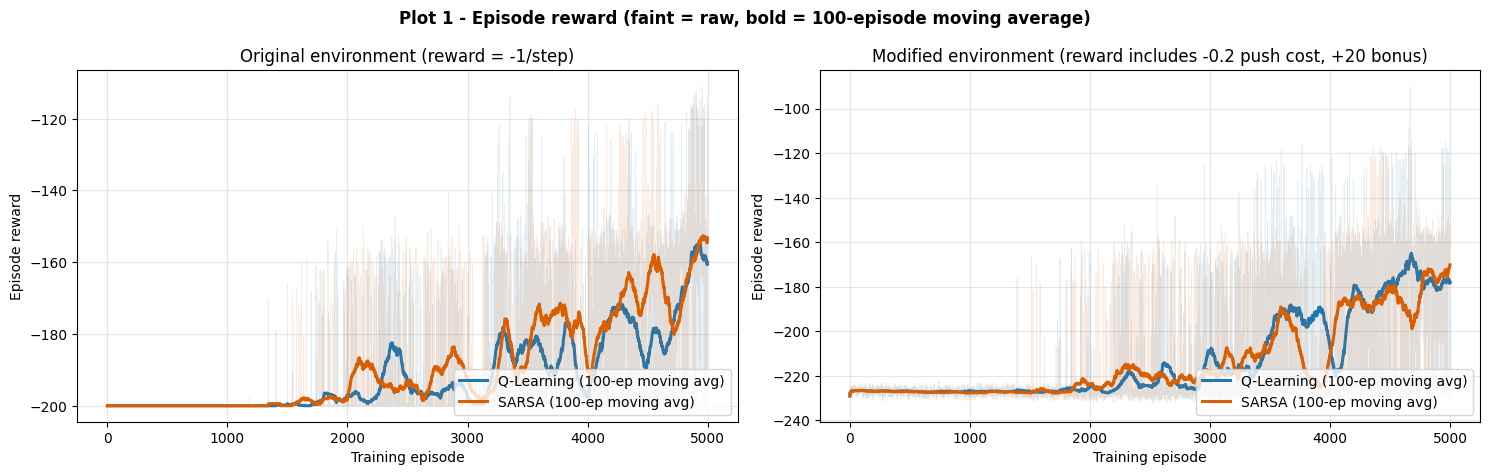

In [15]:
# ---- Plot 1: episode reward vs training episode (raw faint + 100-episode moving average) ----
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8), sharey=False)      # one panel per environment
for ax, env_name in zip(axs, ENVS):                                 # loop over the two environments
    for algo in ALGOS:                                                # both algorithms in the same panel
        r = primary(algo, env_name)["rewards"]                        # per-episode reward of the primary seed
        ax.plot(r, color=COLOR[algo], alpha=0.12, lw=0.6)                                  # raw per-episode reward
        ax.plot(moving_avg(r), color=COLOR[algo], lw=2.2, label=f"{algo} (100-ep moving avg)")  # moving average on top of the raw curve
    ax.set_title(f"{env_name} environment" + (" (reward includes -0.2 push cost, +20 bonus)" if env_name == "Modified" else " (reward = -1/step)"))  # panel title
    ax.set_xlabel("Training episode"); ax.set_ylabel("Episode reward"); ax.grid(alpha=0.3); ax.legend(loc="lower right")  # labels, grid and legend
fig.suptitle("Plot 1 - Episode reward (faint = raw, bold = 100-episode moving average)", fontweight="bold")  # overall title
plt.tight_layout(); plt.show()

For about the first 1,300 to 1,500 episodes nobody reaches the flag, so every episode is cut at 200 steps. The reward is then exactly -200 in the original environment and about -228 in the modified one (-1.14 per step, which means roughly 70% of the random actions are pushes costing 0.2).
After that the rewards go up for all four agents, but the moving averages are very noisy and are still going up at episode 5,000 (around -153 to -160 original, -170 to -178 modified). So we think 5,000 episodes is not enough for full convergence.
Q-learning and SARSA look similar. SARSA is a bit higher at the end in the original environment, and in the modified one the two keep swapping places. The modified rewards are lower because each push costs 0.2 (about 120 pushes is about -24) and the +20 bonus only pays back part of that, so rewards can only be compared inside the same environment.

### Plot 2 - Average predicted value max_a Q(s,a) on the fixed validation set

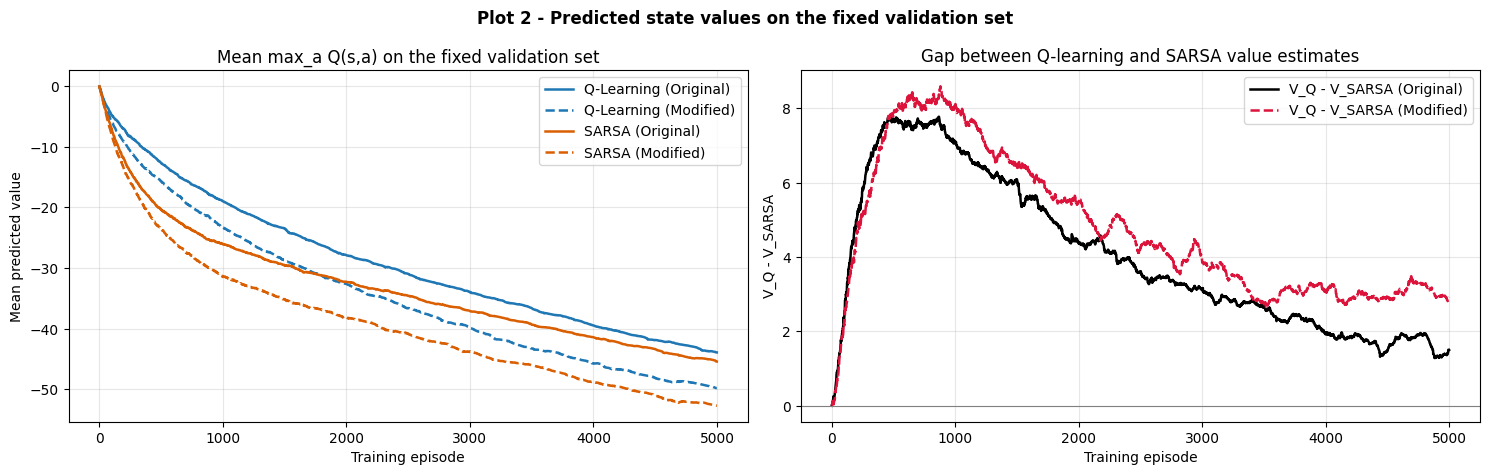

Environment  V_Q (last 100 ep)  V_SARSA (last 100 ep)  V_Q - V_SARSA  |gap|
   Original            -43.723                -45.090          1.367  1.367
   Modified            -49.517                -52.444          2.927  2.927


In [16]:
# ---- Plot 2: mean predicted value max_a Q(s,a) on the fixed validation set; plus the Q-vs-SARSA gap ----
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8))                      # left: values, right: Q-vs-SARSA gap
for algo in ALGOS:                                                # loop over the algorithms
    for env_name in ENVS:                                             # four value curves on the left panel
        axs[0].plot(primary(algo, env_name)["val_v"], color=COLOR[algo], ls=STYLE[env_name], lw=1.8, label=f"{algo} ({env_name})")  # validation value of one agent
axs[0].set_title("Mean max_a Q(s,a) on the fixed validation set"); axs[0].set_xlabel("Training episode")  # title and axis labels of the left panel
axs[0].set_ylabel("Mean predicted value"); axs[0].grid(alpha=0.3); axs[0].legend()  # axis label, grid and legend

for env_name, col in zip(ENVS, ["black", "crimson"]):                    # gap = V_Q - V_SARSA for each environment
    gap = np.array(primary("Q-Learning", env_name)["val_v"]) - np.array(primary("SARSA", env_name)["val_v"])  # difference between the two algorithms
    axs[1].plot(gap, color=col, ls=STYLE[env_name], lw=1.8, label=f"V_Q - V_SARSA ({env_name})")  # plot the gap
axs[1].axhline(0, color="grey", lw=0.8)                           # zero line
axs[1].set_title("Gap between Q-learning and SARSA value estimates"); axs[1].set_xlabel("Training episode")  # title and axis label of the right panel
axs[1].set_ylabel("V_Q - V_SARSA"); axs[1].grid(alpha=0.3); axs[1].legend()  # axis label, grid and legend
fig.suptitle("Plot 2 - Predicted state values on the fixed validation set", fontweight="bold")  # overall title
plt.tight_layout(); plt.show()

# Quantify the Q-vs-SARSA gap (seed 42): final value = mean over the last 100 episodes
rows = []                                                              # table rows: final (last-100-episode) values and gap
for env_name in ENVS:                                             # loop over the environments
    vq = np.mean(primary("Q-Learning", env_name)["val_v"][-100:]); vs = np.mean(primary("SARSA", env_name)["val_v"][-100:])  # final values of both algorithms
    rows.append((env_name, vq, vs, vq - vs, abs(vq - vs)))        # one row per environment
df_gap = pd.DataFrame(rows, columns=["Environment", "V_Q (last 100 ep)", "V_SARSA (last 100 ep)", "V_Q - V_SARSA", "|gap|"])  # gap table
print(df_gap.round(3).to_string(index=False))

All values start at 0 and then go down. This happens because the zero table is optimistic (all real returns are negative) and it is slowly corrected. None of the curves has flattened at episode 5,000, so the absolute levels are not final.
Two things are clear. First, the modified environment has lower values than the original (-49.5 and -52.4 against -43.7 and -45.1 for Q-learning and SARSA at the end), which makes sense because of the push cost and the delays from stuck actuators.
Second, Q-learning is always above SARSA. In the right plot the gap V_Q - V_SARSA grows to about 8 in the first 700 episodes and then shrinks as epsilon decays. At the end it is 1.37 in the original and 2.93 in the modified environment for seed 42,
and 1.58 +- 0.19 against 2.16 +- 0.40 over five seeds. So the gap is bigger with sticky actuators during the second half of training.

### Plot 3 - Success rate and gentle-arrival rate

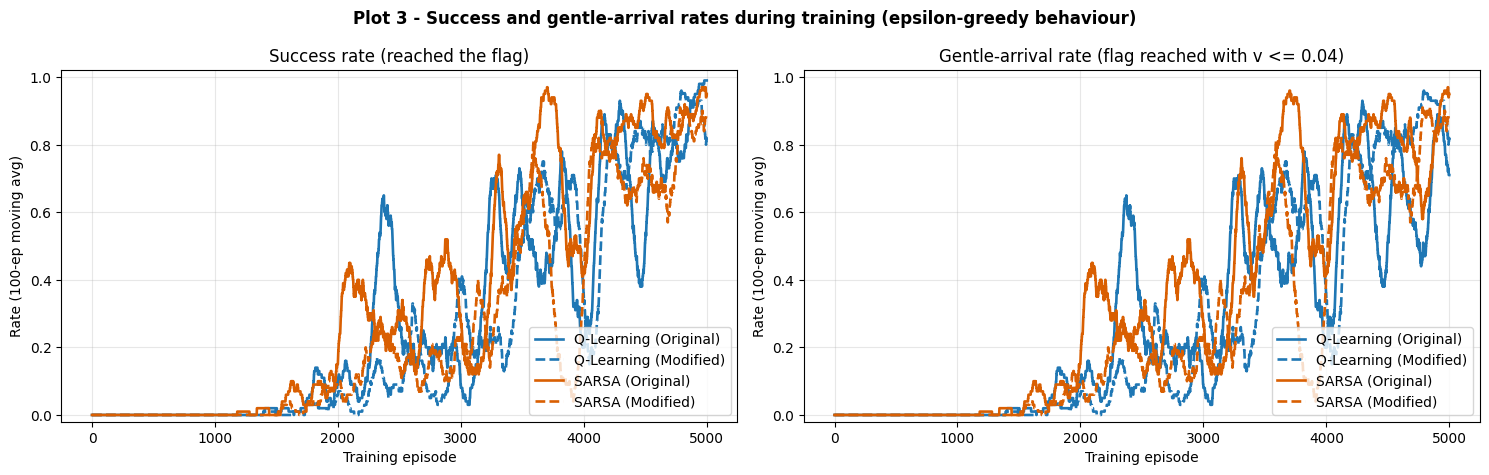

In [17]:
# ---- Plot 3: success rate and gentle-arrival rate (100-episode moving average) for ALL four agents ----
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8))                  # two panels side by side
for key, title, ax in (("success", "Success rate (reached the flag)", axs[0]), ("gentle", "Gentle-arrival rate (flag reached with v <= 0.04)", axs[1])):  # one panel per metric
    for algo in ALGOS:                                                # 4 curves per panel: algorithm x environment
        for env_name in ENVS:                                     # loop over the environments
            ax.plot(moving_avg(primary(algo, env_name)[key]), color=COLOR[algo], ls=STYLE[env_name], lw=1.9, label=f"{algo} ({env_name})")  # moving average of this agent
    ax.set_title(title); ax.set_xlabel("Training episode"); ax.set_ylabel("Rate (100-ep moving avg)")  # labels
    ax.set_ylim(-0.02, 1.02); ax.grid(alpha=0.3); ax.legend(loc="lower right")  # axis limits, grid and legend
fig.suptitle("Plot 3 - Success and gentle-arrival rates during training (epsilon-greedy behaviour)", fontweight="bold")  # overall title
plt.tight_layout(); plt.show()

Success stays at zero until about episode 1,300 to 1,700 and then goes up in noisy steps to roughly 80 to 95%. This is the behaviour during training, so it still has about 3% random actions at the end.
SARSA in the original environment starts learning a bit earlier than the others, but apart from that the four curves cross each other many times, so with one seed we cannot say that one algorithm is clearly better.
The clearest difference is in the right plot. In the modified environment the gentle-arrival curve is the same as the success curve, so every time the car reaches the flag it does so slowly enough to get the +20.
In the original environment there is a gap between the two, because nothing rewards slow arrival (last 500 episodes: Q-learning 85.0% success but only 68.6% gentle, SARSA 87.8% and 81.0%).

### Plot 4 - Push actions per episode

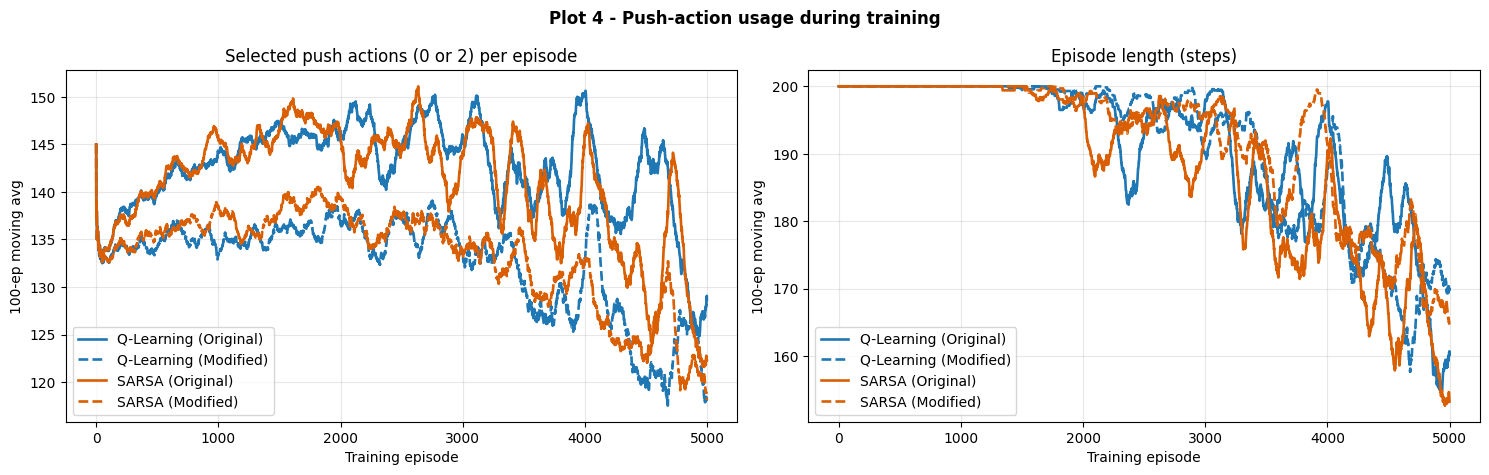

Training statistics over the LAST 500 training episodes:
 Algorithm      Env  Mean pushes/ep  Mean steps/ep  Success %  Gentle %  Mean arrival vel
Q-Learning Original         133.900        168.870       85.0      68.6             0.033
Q-Learning Modified         122.514        168.766       86.4      86.4             0.020
     SARSA Original         130.144        163.870       87.8      81.0             0.031
     SARSA Modified         123.636        171.674       77.8      77.8             0.028


In [18]:
# ---- Plot 4: average number of selected push actions (0 or 2) per episode (+ episode length for context) ----
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8))                  # two panels side by side
for key, title, ax in (("pushes", "Selected push actions (0 or 2) per episode", axs[0]), ("steps", "Episode length (steps)", axs[1])):  # one panel per metric
    for algo in ALGOS:                                            # loop over the algorithms
        for env_name in ENVS:                                     # loop over the environments
            ax.plot(moving_avg(primary(algo, env_name)[key]), color=COLOR[algo], ls=STYLE[env_name], lw=1.9, label=f"{algo} ({env_name})")  # moving average of this agent
    ax.set_title(title); ax.set_xlabel("Training episode"); ax.set_ylabel("100-ep moving avg"); ax.grid(alpha=0.3); ax.legend()  # labels
fig.suptitle("Plot 4 - Push-action usage during training", fontweight="bold")  # overall title
plt.tight_layout(); plt.show()

# Training-tail statistics (last 500 episodes, epsilon ~0.03): pushes, steps, gentle rate, arrival speed
rows = []                                                              # one row per agent: statistics of the last 500 episodes
for algo in ALGOS:                                                # loop over the algorithms
    for env_name in ENVS:                                         # loop over the environments
        r = primary(algo, env_name)                               # result of this agent
        av = np.array(r["arrival_vel"][-500:], dtype=float)       # arrival speeds in the last 500 episodes
        rows.append((algo, env_name, np.mean(r["pushes"][-500:]), np.mean(r["steps"][-500:]),  # statistics of the last 500 episodes
                     100*np.mean(r["success"][-500:]), 100*np.mean(r["gentle"][-500:]), np.nanmean(av) if np.isfinite(av).any() else np.nan))
df_tail = pd.DataFrame(rows, columns=["Algorithm", "Env", "Mean pushes/ep", "Mean steps/ep", "Success %", "Gentle %", "Mean arrival vel"])  # training-tail table
print("Training statistics over the LAST 500 training episodes:"); print(df_tail.round(3).to_string(index=False))

At the beginning the agents choose a push in about 135 to 150 of the 200 steps. During most of training the modified agents (dashed) push less than the original ones, for example around 135 to 138 against 143 to 148 between episodes 500 and 2,500, which fits the 0.2 energy cost.
Later the episodes become shorter (right plot, from 200 down to about 153 to 172 steps) and the push counts drop to about 118 to 129 for all agents.
In the last 500 episodes the modified agents choose 122.5 (Q-learning) and 123.6 (SARSA) pushes per episode, against 133.9 and 130.1 in the original environment. That is about 6 to 8% fewer pushes with a similar episode length (169 to 172 steps).
So the penalty does reduce the pushes, but not by much, which is logical because the car has to pump energy to get up the hill anyway.

### Plot 5 - Greedy policy maps

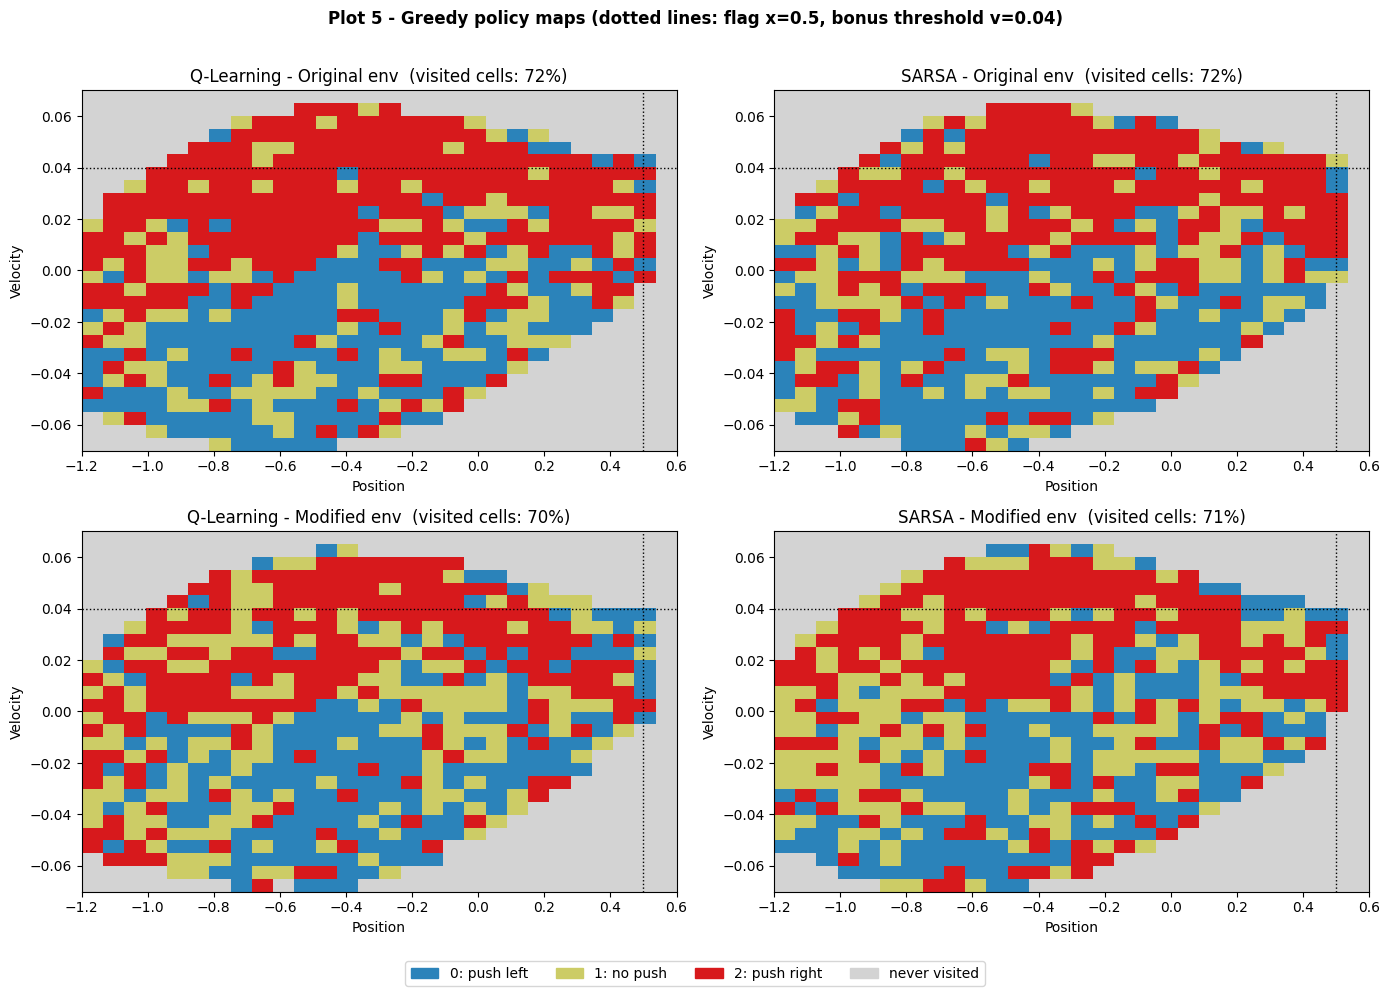

In [19]:
# ---- Plot 5: greedy-policy maps over the position x velocity grid (unvisited cells masked in grey) ----
ACTION_COLORS = ["#2b83ba", "#cccc66", "#d7191c"]                       # 0 left = blue, 1 idle = yellow, 2 right = red
cmap_actions = ListedColormap(ACTION_COLORS)                      # one colour per action
fig, axs = plt.subplots(2, 2, figsize=(14, 10))                       # one heatmap per agent
for ax, (algo, env_name) in zip(axs.ravel(), [("Q-Learning", "Original"), ("SARSA", "Original"), ("Q-Learning", "Modified"), ("SARSA", "Modified")]):  # one panel per agent
    r = primary(algo, env_name)                                   # result of this agent
    greedy = r["q_table"].argmax(axis=2)                                 # greedy action per cell
    seen = r["visits"].sum(axis=2) > 0                                   # cell visited at least once?
    img = np.ma.masked_array(greedy.T, mask=~seen.T)                     # transpose: x = position, y = velocity
    ax.set_facecolor("lightgrey")                                 # grey background shows cells that were never visited
    ax.imshow(img, origin="lower", extent=[-1.2, 0.6, -0.07, 0.07], aspect="auto", cmap=cmap_actions, vmin=-0.5, vmax=2.5, interpolation="nearest")  # draw the greedy action of every cell
    ax.axhline(0.04, color="k", ls=":", lw=1); ax.axvline(0.5, color="k", ls=":", lw=1)   # bonus threshold and flag
    ax.set_title(f"{algo} - {env_name} env  (visited cells: {seen.mean()*100:.0f}%)")  # panel title with the share of visited cells
    ax.set_xlabel("Position"); ax.set_ylabel("Velocity")          # axis labels
handles = [mpatches.Patch(color=ACTION_COLORS[0], label="0: push left"), mpatches.Patch(color=ACTION_COLORS[1], label="1: no push"),  # legend entries
           mpatches.Patch(color=ACTION_COLORS[2], label="2: push right"), mpatches.Patch(color="lightgrey", label="never visited")]  # legend entries (continued)
fig.legend(handles=handles, loc="lower center", ncol=4)           # common legend
fig.suptitle("Plot 5 - Greedy policy maps (dotted lines: flag x=0.5, bonus threshold v=0.04)", fontweight="bold")  # overall title
plt.tight_layout(rect=[0, 0.04, 1, 0.97]); plt.show()

All four maps show the usual swinging strategy: push right (red) when the velocity is positive and push left (blue) when it is negative, with the change around velocity 0.
Only about 70% of the cells were ever visited (grey cells), and the policy in the rarely visited cells is more or less random. This explains the rough boundaries and again suggests that the learning is not finished.
In the modified maps we see more "no push" cells (yellow) in the slow part of the valley, which matches the push cost. Near the flag at velocities above about 0.04 there is also a wider area of left-push or no-push cells (x between 0.2 and 0.5, easiest to see for SARSA modified).
We read this as braking before the flag, which gives the slow arrival. The differences between the Q-learning and SARSA maps are mostly in the rarely visited cells, so we do not see a clear structural difference.

### Final greedy evaluation (epsilon = 0, 100 test episodes with fixed seeds)

In [20]:
# ---- Final greedy evaluation (epsilon = 0) over 100 fixed-seed test episodes, each agent in its own training env ----
eval_rows = {}                                                         # label -> metrics dict
for algo in ALGOS:                                                # loop over the algorithms
    for env_name in ENVS:                                         # loop over the environments
        eval_rows[f"{algo} - {env_name} Env"] = evaluate_greedy_policy(primary(algo, env_name)["q_table"], modified=(env_name == "Modified"))  # evaluate this agent in its own environment
df_eval = pd.DataFrame(eval_rows).T                               # evaluation table
print(f"=== Final evaluation, {EVAL_EPISODES} test episodes (reset seeds {EVAL_BASE_SEED}..{EVAL_BASE_SEED+EVAL_EPISODES-1}), epsilon = 0, training seed {SEED} ===")
print(df_eval.round(3).to_string())
df_eval

=== Final evaluation, 100 test episodes (reset seeds 1000..1099), epsilon = 0, training seed 42 ===
                           Mean Reward  Success Rate (%)  Gentle-Arrival Rate (%)  Mean Episode Length  Mean Pushes / Episode  Mean Arrival Velocity
Q-Learning - Original Env     -141.530             100.0                     67.0               141.53                 117.06                  0.033
Q-Learning - Modified Env     -146.036             100.0                    100.0               143.85                 110.93                  0.017
SARSA - Original Env          -187.030              86.0                     86.0               187.03                 156.02                  0.037
SARSA - Modified Env          -167.544              87.0                     87.0               161.83                 115.57                  0.021


,Mean Reward,Success Rate (%),Gentle-Arrival Rate (%),Mean Episode Length,Mean Pushes / Episode,Mean Arrival Velocity
Q-Learning - Original Env,-141.530,100.0,67.0,141.53,117.06,0.033143
Q-Learning - Modified Env,-146.036,100.0,100.0,143.85,110.93,0.017389
SARSA - Original Env,-187.030,86.0,86.0,187.03,156.02,0.036946
SARSA - Modified Env,-167.544,87.0,87.0,161.83,115.57,0.021332


This table is for seed 42 only.
- Q-learning reaches the flag in 100 of 100 test episodes in both environments, SARSA in 86 (original) and 87 (modified). So seed 42 favours Q-learning, but the next section shows that this is not the typical result.
- The biggest effect of the modified environment is the arrival speed. Q-learning in the original environment is gentle in only 67% of the episodes (mean arrival speed 0.033), while in the modified environment it is gentle in 100% (mean arrival speed 0.017).
  For SARSA the mean arrival speed goes from 0.037 to 0.021 and all successful arrivals are gentle in both environments (86 of 86 and 87 of 87).
- The number of pushes goes from 117.1 to 110.9 for Q-learning and from 156.0 to 115.6 for SARSA (original to modified). As a share of the steps this is 83% to 77% for Q-learning and 83% to 71% for SARSA. The SARSA policy in the original environment is simply slow (187 steps), so its large drop partly comes from that.
- Mean rewards can only be compared inside one environment, because the modified reward includes the push cost and the bonus.

### Extra checks
The assignment asks for a comparison with one seed. While working on it we saw that single runs of tabular RL vary a lot, so we repeated the four trainings with four more seeds,
ran every policy in the other environment as well, and compared the 28 x 28 grid with a 20 x 20 grid. The independent training runs are executed in parallel to save time.

In [21]:
# ---------- Robustness: repeat the four trainings with more seeds (everything else identical) ----------
ALGO_KEY = {"Q-Learning": "q_learning", "SARSA": "sarsa"}         # name used by the training function
jobs, tags = [], []                                               # jobs to run and a label for each
for seed in EXTRA_SEEDS:                                                   # all extra runs are independent -> run together
    for algo in ALGOS:                                            # loop over the algorithms
        for env_name in ENVS:                                     # loop over the environments
            jobs.append(dict(agent_type=ALGO_KEY[algo], modified=(env_name == "Modified"), seed=seed))  # one training job
            tags.append((algo, env_name))                         # label of that job
res = run_parallel(jobs, f"extra seeds {EXTRA_SEEDS}")            # train all extra runs
for tag, r in zip(tags, res):                                     # put every result into RESULTS
    RESULTS[tag].append(r)                                                 # seed order is kept: 42 first, then the extra seeds
report_runs(res)                                                  # print a summary line per run
print("runs per agent:", {f"{k[0]}-{k[1]}": len(v) for k, v in RESULTS.items()})

extra seeds [43, 44, 45, 46]: 16 training runs finished in 146s (parallel, 14 workers)
  q_learning | original | seed 43 | success in last 500 episodes  79.8% | final epsilon 0.0302
  q_learning | modified | seed 43 | success in last 500 episodes  75.8% | final epsilon 0.0302
  sarsa      | original | seed 43 | success in last 500 episodes  76.0% | final epsilon 0.0302
  sarsa      | modified | seed 43 | success in last 500 episodes  57.6% | final epsilon 0.0302
  q_learning | original | seed 44 | success in last 500 episodes  67.4% | final epsilon 0.0302
  q_learning | modified | seed 44 | success in last 500 episodes  69.8% | final epsilon 0.0302
  sarsa      | original | seed 44 | success in last 500 episodes  76.4% | final epsilon 0.0302
  sarsa      | modified | seed 44 | success in last 500 episodes  93.4% | final epsilon 0.0302
  q_learning | original | seed 45 | success in last 500 episodes  74.2% | final epsilon 0.0302
  q_learning | modified | seed 45 | success in last 500 ep

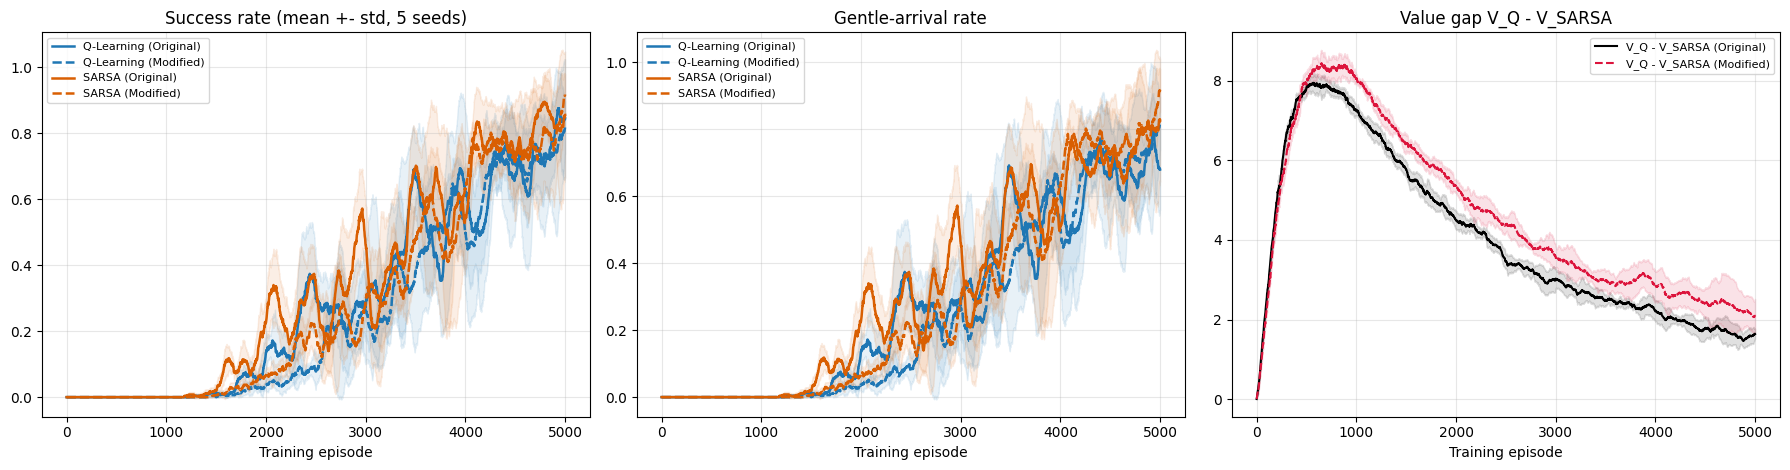

=== Greedy evaluation, mean and std over 5 training seeds ===
                    Mean Reward        Success Rate (%)        Gentle-Arrival Rate (%)        Mean Episode Length        Mean Pushes / Episode        Final V (val, last100)      
                           mean    std             mean    std                    mean    std                mean    std                  mean    std                   mean   std
Algorithm  Env                                                                                                                                                                    
Q-Learning Modified     -173.11  18.42             79.6  15.08                    79.6  15.08              165.16  14.08                117.12   7.88                 -49.79  0.21
           Original     -166.01  18.98             79.8  19.23                    63.2  36.53              166.01  18.98                133.73  13.86                 -43.39  0.19
SARSA      Modified     -161.82  10.31     

In [22]:
# ---- Multi-seed statistics: curves (mean +- std) and final greedy evaluation per seed ----
fig, axs = plt.subplots(1, 3, figsize=(18, 4.8))                      # success | gentle | value gap, mean +- std over seeds
def band(ax, key, algo, env_name, smooth=True):                   # helper: mean and spread over seeds
    """Plot mean +- std across seeds of a per-episode metric."""
    arr = np.array([moving_avg(r[key]) if smooth else np.array(r[key]) for r in RESULTS[(algo, env_name)]])  # one row per seed
    m, s = arr.mean(0), arr.std(0)                                # mean and standard deviation over seeds
    ax.plot(m, color=COLOR[algo], ls=STYLE[env_name], lw=1.8, label=f"{algo} ({env_name})")  # mean curve
    ax.fill_between(np.arange(len(m)), m - s, m + s, color=COLOR[algo], alpha=0.10)  # band of one standard deviation
for algo in ALGOS:                                                # loop over the algorithms
    for env_name in ENVS:                                         # loop over the environments
        band(axs[0], "success", algo, env_name); band(axs[1], "gentle", algo, env_name)  # success and gentle curves
for env_name, col in zip(ENVS, ["black", "crimson"]):                     # value gap per seed -> mean +- std
    gaps = np.array([np.array(a["val_v"]) - np.array(b["val_v"]) for a, b in zip(RESULTS[("Q-Learning", env_name)], RESULTS[("SARSA", env_name)])])  # value gap of every seed
    axs[2].plot(gaps.mean(0), color=col, ls=STYLE[env_name], label=f"V_Q - V_SARSA ({env_name})")  # mean gap
    axs[2].fill_between(np.arange(gaps.shape[1]), gaps.mean(0) - gaps.std(0), gaps.mean(0) + gaps.std(0), color=col, alpha=0.12)  # band of one standard deviation
# titles and axis labels
axs[0].set_title(f"Success rate (mean +- std, {len(ALL_SEEDS)} seeds)"); axs[1].set_title("Gentle-arrival rate"); axs[2].set_title("Value gap V_Q - V_SARSA")  # title and axis labels of the left panel
for ax in axs: ax.set_xlabel("Training episode"); ax.grid(alpha=0.3); ax.legend(fontsize=8)  # labels, grid and legend
plt.tight_layout(); plt.show()

# Final greedy evaluation for EVERY seed (each Q-table evaluated in the env it was trained in)
rows = []                                                              # one row per (agent, seed)
for (algo, env_name), runs in RESULTS.items():                    # every agent and every seed
    for r in runs:                                                # every seed
        m = evaluate_greedy_policy(r["q_table"], modified=(env_name == "Modified"))  # final greedy evaluation of this run
        rows.append({"Algorithm": algo, "Env": env_name, "Seed": r["seed"], **m,  # one row per run
                     "Final V (val, last100)": float(np.mean(r["val_v"][-100:]))})  # final value estimate
df_seeds = pd.DataFrame(rows)                                     # table with all runs
cols = ["Mean Reward", "Success Rate (%)", "Gentle-Arrival Rate (%)", "Mean Episode Length", "Mean Pushes / Episode", "Final V (val, last100)"]  # average number of push actions
summary = df_seeds.groupby(["Algorithm", "Env"])[cols].agg(["mean", "std"]).round(2)  # mean and std over the seeds
print(f"=== Greedy evaluation, mean and std over {len(ALL_SEEDS)} training seeds ===")
print(summary.to_string())
print("\nPer-seed success rates (%):")
print(df_seeds.pivot_table(index=["Algorithm", "Env"], columns="Seed", values="Success Rate (%)").to_string())

# Paired comparison Q-learning vs SARSA per environment (same seeds): positive = SARSA better
print("\nPaired difference SARSA - Q-learning (per-seed greedy success %, mean +- std; wins = #seeds SARSA > Q):")
for env_name in ENVS:                                             # loop over the environments
    q_s = df_seeds[(df_seeds.Algorithm == "Q-Learning") & (df_seeds.Env == env_name)].sort_values("Seed")["Success Rate (%)"].to_numpy()  # Q-learning success per seed
    s_s = df_seeds[(df_seeds.Algorithm == "SARSA") & (df_seeds.Env == env_name)].sort_values("Seed")["Success Rate (%)"].to_numpy()  # SARSA success per seed
    print(f"  {env_name:8s}: {np.mean(s_s - q_s):6.1f} +- {np.std(s_s - q_s):5.1f}   wins {int((s_s > q_s).sum())}/{len(q_s)}")
print("\nValue gap |V_Q - V_SARSA| (last 100 episodes), mean +- std over seeds:")
for env_name in ENVS:                                             # loop over the environments
    g = [abs(np.mean(a["val_v"][-100:]) - np.mean(b["val_v"][-100:])) for a, b in zip(RESULTS[("Q-Learning", env_name)], RESULTS[("SARSA", env_name)])]  # absolute value gap per seed
    print(f"  {env_name:8s}: {np.mean(g):6.3f} +- {np.std(g):5.3f}")

The shaded bands (standard deviation over seeds) overlap a lot, so single curves are really noisy. The main numbers for the greedy evaluation (mean +- std over seeds 42 to 46) are:

| Environment | Q-learning success | SARSA success | Q-learning mean reward | SARSA mean reward |
|---|---|---|---|---|
| Original | 79.8 +- 19.2 % | 81.8 +- 22.6 % | -166.0 +- 19.0 | -177.7 +- 17.5 |
| Modified | 79.6 +- 15.1 % | 94.8 +- 5.6 % | -173.1 +- 18.4 | -161.8 +- 10.3 |

In the original environment there is no real difference (SARSA minus Q-learning is +2.0 points with a std of 27, and SARSA wins in 3 of 5 seeds).
In the modified environment SARSA is better on average (+15.2 points, wins in 4 of 5 seeds) and also much more stable (std 5.6 against 15.1). With only five seeds this is a hint and not a proof (paired t is about 2.0, p about 0.12). Seed 42, the one used in the main comparison, is actually the seed where Q-learning wins most clearly.
The value gap |V_Q - V_SARSA| is 1.58 +- 0.19 in the original and 2.16 +- 0.40 in the modified environment, so it is larger with sticky actuators, but it is also shrinking at the end of training.
In the modified environment the gentle-arrival rate equals the success rate for every seed (94.8 and 79.6 on average), while in the original environment it is lower and changes a lot from seed to seed (63.2 +- 36.5 for Q-learning).

In [23]:
# ---- Cross-evaluation: each primary-seed greedy policy run in BOTH environments ----
rows = []                                                              # one row per trained policy
for algo in ALGOS:                                                # loop over the algorithms
    for train_env in ENVS:                                        # environment the policy was trained in
        q_tab = primary(algo, train_env)["q_table"]               # Q-table of this policy
        m_o = evaluate_greedy_policy(q_tab, modified=False); m_m = evaluate_greedy_policy(q_tab, modified=True)  # run it in both environments
        rows.append((algo, train_env, m_o["Success Rate (%)"], m_m["Success Rate (%)"], m_o["Mean Episode Length"], m_m["Mean Episode Length"]))  # one row per policy
df_cross = pd.DataFrame(rows, columns=["Algorithm", "Trained in", "Success % (run in Original)", "Success % (run in Modified)",  # cross-evaluation table
                                       "Mean length (Original)", "Mean length (Modified)"])  # column names (continued)
print(df_cross.round(2).to_string(index=False))

 Algorithm Trained in  Success % (run in Original)  Success % (run in Modified)  Mean length (Original)  Mean length (Modified)
Q-Learning   Original                        100.0                         98.0                  141.53                  144.32
Q-Learning   Modified                        100.0                        100.0                  144.40                  143.85
     SARSA   Original                         86.0                         77.0                  187.03                  182.42
     SARSA   Modified                         83.0                         87.0                  161.85                  161.83


Policies trained in one environment work well in the other. Q-learning trained in the original environment loses only 2 points when it is run with sticky actuators (100% to 98%, 141.5 to 144.3 steps), and Q-learning trained in the modified environment gets 100% in both.
The SARSA policies change by 4 to 9 points (86% to 77% for the original-trained one, 83% to 87% for the modified-trained one).
So the greedy policies are not really specialised for the sticky actuator. We think this is because a stuck action only lasts one step and the car has a lot of momentum. It also explains why the difference between the algorithms is hard to see with 5,000 episodes.

In [24]:
# ---- Grid-size check: 20x20 vs 28x28 (modified env, seed 42) ----
jobs = [dict(agent_type=ALGO_KEY[a], modified=True, seed=SEED, n_bins=20) for a in ALGOS]  # 20x20 runs (the 28x28 runs already exist)
res20 = run_parallel(jobs, "20x20 grid")                                   # the 28x28 runs already exist in RESULTS
rows = []                                                                  # one row per (grid, algorithm)
for n_b, runs in ((20, res20), (N_BINS, [RESULTS[(a, "Modified")][0] for a in ALGOS])):  # compare the two grid sizes
    for algo, res_i in zip(ALGOS, runs):                          # one row per algorithm
        m = evaluate_greedy_policy(res_i["q_table"], modified=True, n_bins=n_b)  # greedy evaluation
        rows.append((f"{n_b}x{n_b}", algo, np.mean(res_i["success"][-500:])*100, m["Success Rate (%)"], m["Gentle-Arrival Rate (%)"], m["Mean Episode Length"], m["Mean Reward"]))  # one row per grid and algorithm
df_abl = pd.DataFrame(rows, columns=["Grid", "Algorithm", "Train success % (last 500)", "Eval success %", "Eval gentle %", "Eval mean length", "Eval mean reward"])  # grid comparison table
print(df_abl.round(2).to_string(index=False))

20x20 grid: 2 training runs finished in 34s (parallel, 2 workers)
 Grid  Algorithm  Train success % (last 500)  Eval success %  Eval gentle %  Eval mean length  Eval mean reward
20x20 Q-Learning                        87.4           100.0          100.0            157.44           -157.28
20x20      SARSA                        78.2           100.0          100.0            159.33           -158.98
28x28 Q-Learning                        86.4           100.0          100.0            143.85           -146.04
28x28      SARSA                        77.8            87.0           87.0            161.83           -167.54


The smaller 20 x 20 grid learned at least as well as the 28 x 28 grid in the same 5,000 episodes (greedy success 100% for both algorithms, against 100% and 87%; success in the last 500 training episodes 87.4% and 78.2% against 86.4% and 77.8%).
The finer grid has almost twice as many cells to learn, so it did not help in this budget. Our reason for choosing 28 x 28 was that one bin edge sits exactly at the 0.04 threshold, not that it performs better. This is only one seed, so we do not want to read too much into it.

## (e) Discussion
We use Plot 2 and the value-gap table for Q1, the push plot, policy maps and arrival statistics for Q3, the multi-seed results for Q4,
and an experiment that we actually ran (adding `a_prev` to the state) for Q5.

### Q1. Does the sticky actuator increase the difference between the value estimates of Q-learning and SARSA?
Yes, but only a little. In Plot 2 (right) and the gap table, the final gap V_Q - V_SARSA (mean of the last 100 episodes) is 1.37 in the original and 2.93 in the modified environment for seed 42, and over five seeds it is 1.58 +- 0.19 against 2.16 +- 0.40.
Q-learning is above SARSA in both environments during the whole training.

Our explanation is that Q-learning bootstraps from the maximum over the next actions, so it assumes the best action will be taken, while SARSA bootstraps from the action that the epsilon-greedy policy really takes, including the random ones.
With sticky actuators a random action costs more (a change of action is delayed in 20% of the cases and every push costs 0.2), so the value of the policy that is actually followed drops more than the value of the greedy policy, and the gap gets bigger.

We should add some warnings. The gap is not stable: it peaks at about 8 after roughly 700 episodes and then shrinks while epsilon decays, and all values are still going down at episode 5,000. The extra gap in the modified environment (+1.6 for seed 42, +0.6 averaged over seeds) is only about 1.5 to 3 times the seed-to-seed std, so it points in the right direction but is not big.

### Q2. Why is the modified environment non-Markovian for the observation, and what does this do to credit assignment?
The agent only sees position and velocity. But the action that is really executed, and so the next state, also depends on the hidden `a_prev`. For example, if the agent chooses action 2, the car is pushed right with probability 1 when `a_prev` is 2, but only with probability 0.8 when `a_prev` is 0 (the other 20% it is pushed left).
So the next state is not decided by the current observation and action alone, it also depends on the history that the agent cannot see. This is exactly what non-Markovian means here (the problem is a POMDP): the same observed (s, a) can lead to different transitions.

For credit assignment this causes several problems. The update always gives the credit or blame to the chosen action `a`, but what really moved the car was `a_exec`, which is `a_prev` when the actuator is stuck, so a reward can be given to an action that was never executed.
Q(s, a) also becomes an average over the unknown values of `a_prev`, and how often each value happens depends on the current policy and on epsilon, so the targets keep changing while we learn.
The TD updates then pass this error backwards through bootstrapping. The energy cost is also charged to the chosen action even if the actuator was stuck, and the +20 bonus can be paid for an arrival that was really caused by a push some steps earlier, so rewards and causes do not match well.
For Q-learning there is one more issue: the max in its target assumes that the next chosen action will be executed, and the hidden stickiness breaks that assumption.

### Q3. Do the energy penalty and the gentle-arrival bonus encourage fewer pushes or a slower, more controlled arrival?
Both, but the effect on the arrival speed is much stronger than the effect on the number of pushes.

Fewer pushes: in the last 500 training episodes the modified agents choose 122.5 (Q-learning) and 123.6 (SARSA) pushes per episode, against 133.9 and 130.1 in the original environment, which is about 6 to 8% fewer with a similar episode length (169 to 172 steps).
The dashed lines in Plot 4 are below the solid ones for most of the training. In the greedy evaluation the pushes per episode go from 117.1 to 110.9 for Q-learning and from 156.0 to 115.6 for SARSA, so the share of steps with a push goes from 83% to 77% and from 83% to 71%.
The saving is small because the car has to pump energy against gravity anyway.

Slower arrival: the mean arrival speed of the greedy policies drops from 0.033 to 0.017 for Q-learning and from 0.037 to 0.021 for SARSA, and the gentle-arrival rate of Q-learning goes from 67% to 100%.
In the modified environment all successful arrivals are gentle (gentle equals success in Plot 3, in training and in evaluation), while in the original environment some arrivals are still fast at the end of training (Q-learning: 68.6% gentle out of 85.0% successful, so about 19% of the arrivals are fast; SARSA: 81.0% out of 87.8%, about 8%).
The policy maps also show a wider area of left-push or no-push cells at velocities above 0.04 near the flag, and more no-push cells in the valley.
The bonus (+20) is worth about 17 steps of the normal cost (1.2 per step) while arriving slowly costs only a few steps, so learning to brake clearly pays off. Even without any incentive most arrivals in the original environment are already slow (see the gap between success and gentle in Plot 3), so the bonus mostly removes the remaining fast arrivals.

### Q4. Which algorithm performs better under sticky actuators? Is this consistent with the theory?
On average SARSA does better and is more stable with sticky actuators, but we only have five seeds, so we see it as a hint and not as a proven result. In the modified environment the greedy success rate over five seeds is 94.8 +- 5.6% for SARSA and 79.6 +- 15.1% for Q-learning, the mean reward is -161.8 against -173.1, and SARSA wins in 4 of 5 seeds (paired difference +15.2 points, t about 2.0, p about 0.12).
In the original environment there is no difference (81.8% against 79.8%, SARSA wins 3 of 5), so the advantage only shows up when the actuator is sticky.
With seed 42, the setting of the main comparison, the order is the opposite (Q-learning 100%, SARSA 87%), so a conclusion from one seed would have been wrong.

This is consistent with the theory in a qualitative way. Q-learning learns the value of the greedy policy and assumes it will be executed correctly, so its targets ignore the cost of switching actions under stickiness and the cost of exploration. SARSA learns the value of the policy it really follows, including random switches and what happens after them, and that tends to give safer values and less variance between runs (the same idea as in the cliff-walking example).
We cannot say that SARSA is always better: in the original deterministic environment the two are about equal in our runs, and with five seeds and tables that are not fully converged (Plot 2 is still moving) more seeds would be needed to be sure.

### Q5 experiment - adding the executed previous action to the state

In [25]:
# ---- Extension for Q5: put the executed previous action a_prev into the state -> (pos_bin, vel_bin, a_prev) ----
# The augmented table has 3x more rows, so it needs more experience. To compare fairly, the plain (x,v) agent is
# also trained for the same longer budget (20,000 episodes; epsilon reaches its floor 0.01 after ~6,600 episodes).
AUG_SEEDS = ALL_SEEDS[:2]                                         # seeds used in the extension
AUG_EPISODES = 20000 if not QUICK_TEST else EPISODES              # longer training budget
jobs, tags = [], []                                               # jobs to run and a label for each
for algo in ALGOS:                                                # loop over the algorithms
    for seed in AUG_SEEDS:                                        # every extension seed
        jobs.append(dict(agent_type=ALGO_KEY[algo], modified=True, seed=seed, episodes=AUG_EPISODES));                         tags.append((algo, seed, "plain long"))  # plain agent, long budget
        jobs.append(dict(agent_type=ALGO_KEY[algo], modified=True, seed=seed, episodes=EPISODES, augment_a_prev=True));        tags.append((algo, seed, "aug 5k"))  # augmented agent, normal budget
        jobs.append(dict(agent_type=ALGO_KEY[algo], modified=True, seed=seed, episodes=AUG_EPISODES, augment_a_prev=True));    tags.append((algo, seed, "aug long"))  # augmented agent, long budget
res = run_parallel(jobs, "extension runs")                        # train all extension runs together
trained = {tag: r for tag, r in zip(tags, res)}                   # look up a result by its label

rows = []                                                                  # one row per (algorithm, seed)
for algo in ALGOS:                                                # loop over the algorithms
    for seed in AUG_SEEDS:                                        # every extension seed
        plain_5k = [r for r in RESULTS[(algo, "Modified")] if r["seed"] == seed][0]      # (x,v), 5,000 episodes, trained earlier
        m = {"plain 5k":   evaluate_greedy_policy(plain_5k["q_table"], True),  # evaluate the four variants
             "plain long": evaluate_greedy_policy(trained[(algo, seed, "plain long")]["q_table"], True),  # plain agent, long budget
             "aug 5k":     evaluate_greedy_policy(trained[(algo, seed, "aug 5k")]["q_table"], True, augment_a_prev=True),  # augmented agent, normal budget
             "aug long":   evaluate_greedy_policy(trained[(algo, seed, "aug long")]["q_table"], True, augment_a_prev=True)}  # augmented agent, long budget
        rows.append({"Algorithm": algo, "Seed": seed,             # one row per algorithm and seed
                     **{f"Success % ({k})": v["Success Rate (%)"] for k, v in m.items()},  # success columns
                     **{f"Mean reward ({k})": v["Mean Reward"] for k, v in m.items()},  # reward columns
                     **{f"Mean length ({k})": v["Mean Episode Length"] for k, v in m.items()}})  # length columns
df_aug = pd.DataFrame(rows)                                       # extension table
print(f"(x,v) = plain agent, (x,v,a_prev) = augmented agent; 5k = 5,000 episodes, long = {AUG_EPISODES} episodes. Greedy evaluation, modified env.")
print(df_aug.round(2).T.to_string(header=False))
print("\nMean over seeds:"); print(df_aug.groupby("Algorithm").mean(numeric_only=True).drop(columns="Seed").round(2).T.to_string())

extension runs: 12 training runs finished in 343s (parallel, 12 workers)
(x,v) = plain agent, (x,v,a_prev) = augmented agent; 5k = 5,000 episodes, long = 20000 episodes. Greedy evaluation, modified env.
Algorithm                 Q-Learning  Q-Learning   SARSA   SARSA
Seed                              42          43      42      43
Success % (plain 5k)           100.0        77.0    87.0   100.0
Success % (plain long)          99.0        97.0   100.0    98.0
Success % (aug 5k)               0.0         1.0     0.0     0.0
Success % (aug long)            96.0       100.0    87.0    92.0
Mean reward (plain 5k)       -146.04     -172.54 -167.54  -160.8
Mean reward (plain long)     -140.38     -143.18 -120.38 -140.88
Mean reward (aug 5k)         -228.08     -228.84 -227.69 -228.86
Mean reward (aug long)       -177.27      -135.9 -160.81 -153.19
Mean length (plain 5k)        143.85      164.98  161.83  157.04
Mean length (plain long)      140.22      141.29  121.01  142.83
Mean length (aug 

### Q5. One limitation and one improvement
Limitation: the agent does not see `a_prev`, but the dynamics depend on it (Q2). The table over (position, velocity) therefore learns values that are averaged over an unknown, policy-dependent mix of `a_prev` values, which makes the TD targets noisy. A second limitation, which we saw in all the plots, is that 5,000 episodes are not enough for the tables to converge (the values in Plot 2 are still falling, about 30% of the cells are never visited) and that the results change a lot from seed to seed.

Improvement: add the executed previous action to the state, so the state is (position bin, velocity bin, `a_prev`) and the table has size 28 x 28 x 3 x 3. Then the transition probabilities are known from the state and the chosen action (executed with probability 0.8 if it differs from `a_prev`, always if it is the same), so the problem is Markov again. We implemented this above for the modified environment, using two seeds and comparing it with the normal agent trained for the same number of episodes.

What we found: with the normal 5,000 episodes the augmented agent learned nothing (0% success, mean reward about -228), because it has three times more cells to fill and most of them are visited very rarely. With 20,000 episodes it works well, but it is not better than the normal agent trained for the same time.
For Q-learning both reach 98% success on average (mean reward -156.6 augmented against -141.8 normal). For SARSA the augmented agent reaches 89.5% against 99% for the normal agent (mean reward -157.0 against -130.6), and the augmented agents also need more steps (about 154 against 132 to 141).
So in our experiment adding `a_prev` did not give a benefit. The larger table costs more than the missing information, at least with this amount of training and only two seeds. What helped much more was simply training longer: the normal agents went from 88.5% (Q-learning) and 93.5% (SARSA) with 5,000 episodes to 98% and 99% with 20,000 episodes.

Because of this, we think the main limit in our setup is the training budget and the size of the table, and not only the hidden variable. Ideas for improvement are longer training or a faster epsilon decay, n-step returns or eligibility traces to pass the rewards back faster, and function approximation that shares information between neighbouring cells instead of a separate table entry for each one.

## Run log

In [26]:
RUN_END = datetime.datetime.now()                                       # end timestamp (for the virtual-lab log)
print("Run finished :", RUN_END.strftime("%Y-%m-%d %H:%M:%S"))
print("Total runtime: %.1f minutes" % ((RUN_END - RUN_START).total_seconds() / 60))

Run finished : 2026-11-06 00:23:31
Total runtime: 10.2 minutes


---
### 📷 Virtual-lab screenshot 3 - End of the run
> **[PLACEHOLDER - paste the screenshot here and delete this box]**
> Screenshot of the output of the run-log cell above: **'Run finished : <date time>'** and **'Total runtime'**. It proves that the whole notebook was executed in the virtual lab.
>
> *Tip: in Jupyter drag the image file into this cell, or use `![screenshot](your_file.png)` with the picture next to the notebook. When exporting to PDF, check that the image appears.*

---